In [49]:
import pandas as pd
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

### Diplomatura en Ciencia de Datos 2025 (Trabajo Práctico 1)
# M18: Lectura Distante de Canciones Argentinas
---

- Iván Kwist
- Lautaro Puican Bertone
- Sofía Perón Santana

### Marco Teórico

Este proyecto busca analizar un dataset conformado por aproximadamente 30000 letras de canciones argentinas extraídas del sitio La Cuerda y posteriormente combinados con información proveniente de la API de Spotify. El objetivo es realizar un análisis cultural sobre este conjunto de datos utilizando procesamiento de lenguaje natural (NLP). Este tipo de estrategias que consisten en utilizar herramientas estadísticas para analizar conjuntos masivos de textos se conocen como *Lectura Distante*.

# 1 - Descripción del dataset

En primer lugar, se realizó una exploración y descripción del conjunto de datos elegido.

In [50]:
url = 'https://github.com/fcalabrow/diplodatos_lacuerda/blob/92187557897f46138e1132c7c2c0610e0683371b/dataset.csv?raw=true'
original_dataset = pd.read_csv(url, index_col=0)

### Tamaño

Utilizando herramientas clásicas de la librería `pandas` analizamos el tamaño y estructura del conjunto de datos.  

In [51]:
print(original_dataset.shape)
print(original_dataset.info())

(34287, 10)
<class 'pandas.core.frame.DataFrame'>
Index: 34287 entries, 0 to 34286
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   song_name     34287 non-null  object 
 1   artist_name   34287 non-null  object 
 2   lyrics        33651 non-null  object 
 3   estilo        34287 non-null  object 
 4   song_url      34287 non-null  object 
 5   album         24186 non-null  object 
 6   release_date  24186 non-null  object 
 7   track_name    24186 non-null  object 
 8   duration_ms   24186 non-null  float64
 9   popularity    24186 non-null  float64
dtypes: float64(2), object(8)
memory usage: 2.9+ MB
None


El conjunto de datos consiste de **34287 elementos** (filas) con **10 atributos** (columnas).

A continuación se detallan las variables, sus tipos y sus fuentes:

- Identificadoras (LaCuerda.net)
    - **song_name**: Nombre de la canción.
    - **artist_name**: Nombre del artista.
    - **lyrics**: Letra de la canción.
    - **song_url**: URL de la canción.


- Identificadoras (Spotify)
    - **track_name**: El nombre del tema.
    - **album**: El nombre del álbum.

- Numéricas (Spotify)
    - **duration_ms**: La duración del tema en milisegundos.
    - **release_date**: Fecha de lanzamiento del álbum.
    - **popularity**: Popularidad del tema según el algoritmo de Spotify [3].

- Categóricas (LaCuerda.Net)
    - **estilo**: El estilo o "género" del tema. Puede ser "bal" (balada), "can" (cantautor), "gru" (grupero), "pop", "rel" (religioso), "rok" (rock), "rom" (romántico), "tra" (tradicional), "tro" (tropical).

Notar que `song_name` y `track_name` son diferentes ya que provienen de fuentes distintas. Es decir, puede haber variaciones asociadas a la versión, edición, etc. En general, los datos de LaCuerda.Net fueron obtenidos utilizando web scrapping en el sitio mientras que los de Spotify se combinaron directamente desde su API.

## Curaduría de datos

Antes de estudiar los registros duplicados, analizamos los registros faltantes y limpiaremos el dato de mayor interés y con más ruido: la letra de las canciones.

### Valores faltantes

Se observa que existen valores faltantes en varias categorías. En particular, se puede ver que aproximadamente un tercio de los datos no cuentan con la información de Spotify.

In [52]:
original_dataset.isna().sum()

song_name           0
artist_name         0
lyrics            636
estilo              0
song_url            0
album           10101
release_date    10101
track_name      10101
duration_ms     10101
popularity      10101
dtype: int64

Utilizando la librería `missingno` se puede visualizar que al menos en la mayoría de los casos si falta uno de los datos de Spotify faltan todos.

<Axes: >

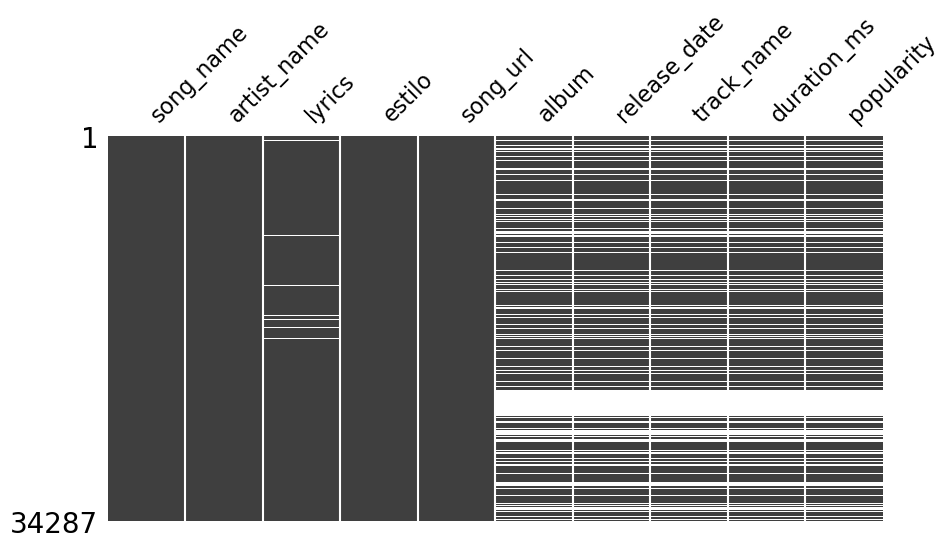

In [53]:
msno.matrix(original_dataset, figsize=(10, 5), sparkline=False)

Además, hay 636 registros (~0.02%) que no cuentan con letra en la canción. Dado que nuestro análisis se concentrará en el análisis de letras, tiene sentido eliminar estas filas.

In [54]:
filtered_dataset = original_dataset[original_dataset['lyrics'].notna()]

### Limpieza de letras

Previo al análisis más minucioso del conjunto de datos diseñamos un pipeline modular que permita limpiar "ruido" asociado a las letras, por ejemplo: los acordes que se encuentran entre líneas debido a tratarse de un sitio de partituras de guitarra.

En detalle:

1. Líneas de tablaturas / cifrados de guitarra

  Ejemplos:
  E|----0---2---|
  a|-0-2-3-0-0-|
  
  Función: remove_tabs_and_loose_chords
2. Acordes musicales, en español e inglés, y sus variantes

  Ejemplos:
  Do, Re, Am7, G, Bdim, Sol#m, etc.
  Acordes sueltos o embebidos en la línea.

  Función: remove_tabs_and_loose_chords, remove_inline_chords
3. Eliminación de partes de estructura de la canción

  Ejemplos:
  Intro:, Verso:, Estribillo, Puente:, Estrofa:, Riff, Punteo, Arpegio, etc.
  Se eliminan siempre al detectar esos encabezados, por estar ahora en signature_keywords.
4. Eliminación total de líneas con números

  Ejemplos:
  14-15-17-14-15-, VI- 0-2-3, cualquier consulta al 1123456789.
  Quita todas las líneas que incluyan algún dígito.
  
  Función: remove_lines_with_numbers
5. Eliminación de URLs y correos electrónicos

  Ejemplos:
  www.ejemplo.com, https://x.com, alguien@mail.com
  
  Función: remove_urls_and_emails
6. Eliminación de HTML y normalización de saltos de línea

  Quita cualquier <div>, <span>, <br>, etc. Convierte <br> y variantes a saltos de línea estándar.
  
  Funciones: normalize_linebreaks, remove_html
7. Eliminación de spam, firma, fuente, créditos y agradecimientos

  Si una línea contiene palabras clave como:
  musica:, fuente:, subido por, facebook, youtube, instagram, mail, correo,
  y ahora también partes de estructura (ej: intro:, estrofa:, etc.),
  el pipeline corta y pone fin al texto lírico desde ahí en adelante.
  
  Función: control por signature_keywords en el loop de cleaning.
8. Eliminación y normalización de puntuación

  Borra . , : ; ! ¿ ? ( ) [ ] " ' - y otros signos de puntuación.
  
  Función: remove_punctuation
9. Normalización y compresión final

  Convierte texto a minúsculas, elimina espacios múltiples y entrega texto sin basura, ideal para análisis/filtros/modelos.
  
  Integrado al final de clean_lyrics

Se agregaron otras columnas asociadas a estas transformaciones. Por un lado estadísticas / numéricas:

- `len_original`: cantidad de caracteres en la letra original.
- `len_final`: cantidad de caracteres en la letra limpia.
- `pct_reduction`: Representa el porcentaje de reducción en la longitud de la letra después de aplicar el pipeline de limpieza. Se calcula como la proporción de caracteres eliminados respecto al largo original de la letra: (len_original - len_final) / len_original.

También se agregaron las letras en distintas instancias del pipeline:

- `lyrics_original`: Contiene la letra original tal como fue extraída del sitio, sin ningún tipo de procesamiento.
- `lyrics_clean_initial`: Letra tras una primera etapa de limpieza básica (normalización de mayúsculas/minúsculas, eliminación de HTML, etc.).
- `lyrics_no_signature`: Letra recortada en caso de detectarse una firma; contiene solo el texto anterior a la misma.
- `lyrics_clean_final`: Letra completamente limpia, tras aplicar todas las etapas del pipeline (remoción de acordes, líneas basura, firmas, etc.).

La siguiente celda contiene las distintas funciones de limpieza. Es muy conveniente su estructura modular ya que puede utilizarse fácilmente sobre distintos conjuntos de datos. Además, permite agregar diferentes expresiones para limpiar de las letras.


In [55]:
import pandas as pd
import re
import string


# --- FUNCIONES ATÓMICAS (puedes añadir más) ---

def normalize_linebreaks(text: str) -> str:
    return re.sub(r'<br\s*/?>', '\n', text, flags=re.IGNORECASE)

def remove_html(text: str) -> str:
    return re.sub(r'<[^>]+>', '', text)

def remove_urls_and_emails(text: str) -> str:
    text = re.sub(r"https?://\S+|www\.\S+", ' ', text)
    text = re.sub(r"\b[\w\.-]+@[\w\.-]+\.\w{2,4}\b", ' ', text)
    return text

def remove_punctuation(text: str) -> str:
    return text.translate(str.maketrans("", "", string.punctuation))

def remove_tabs_and_loose_chords(text: str) -> str:
    tab_line_pattern = r'^[EBGDATeBGDAt]{1}\|[-0-9hpxb/]+.*$'
    chord_pattern_loose = (
        r'\b(?:Do|Re|Mi|Fa|Sol|La|Si|[A-G])'
        r'(?:#|b)?'
        r'(?:m|M|maj|min|sus|dim|aug|add)?'
        r'[0-9]*\b'
    )
    lines = text.split('\n')
    cleaned_lines = []
    for line in lines:
        if re.match(tab_line_pattern, line.strip()):
            continue
        cleaned_line = re.sub(chord_pattern_loose, '', line, flags=re.IGNORECASE)
        cleaned_line = re.sub(r'\s+', ' ', cleaned_line).strip()
        if cleaned_line:
            cleaned_lines.append(cleaned_line)
    return '\n'.join(cleaned_lines)

def remove_lines_with_numbers(text: str) -> str:
    lines = text.split('\n')
    cleaned_lines = [line for line in lines if not re.search(r'\d', line)]
    return '\n'.join(cleaned_lines)

def is_chord_word(word: str) -> bool:
    acorde = r'^[a-gA-G][#b]?(maj|min|m|dim|aug|sus|add)?\d*([/#b]?[a-gA-G\d]*)?\*?$'
    return re.fullmatch(acorde, word.strip()) is not None

def is_chord_line(line: str) -> bool:
    words = [w for w in line.strip().split() if w]
    return len(words) > 0 and all(is_chord_word(w) for w in words)

def is_signature_line(line: str, signature_keywords) -> bool:
    line_low = line.lower().strip()
    if any(line_low.startswith(jk) for jk in signature_keywords):
        return True
    if is_chord_line(line):
        return True
    if re.search(r"https?://|www\.", line_low):
        return True
    if re.search(r"\b[\w\.-]+@[\w\.-]+\.\w{2,4}\b", line_low):
        return True
    return False

def remove_inline_chords(line: str) -> str:
    acorde = r'\b[a-gA-G][#b]?(maj|min|m|dim|aug|sus|add)?\d*([/#b]?[a-gA-G\d]*)?\*?\b'
    return re.sub(acorde, '', line)

# --- CLEAN LYRICS FULLY MODULAR FUNCTION ---
def clean_lyrics(text: str, signature_keywords=None) -> str:
    """
    Limpia letras usando sólo funciones atómicas y corta desde firmas.
    """
    if not isinstance(text, str):
        return ""
    if signature_keywords is None:
        signature_keywords = [
            "musica:", "música:", "acordes:", "fuente:", "subido por", "facebook",
            "youtube", "instagram", "firma", "gracias", "mail", "correo",
            "compartido", "spotify",
                # Estructura de canciones:
            "intro:", "verso:", "estrofa:", "estribillo:", "puente:", "riff:", "punteo:", "arpegio:"
        ]
    # Cleaning pipeline con modulación
    text = normalize_linebreaks(text)
    text = remove_html(text)
    text = remove_urls_and_emails(text)
    text = remove_tabs_and_loose_chords(text)
    text = remove_lines_with_numbers(text)
    text = remove_punctuation(text)


    # Procesa línea a línea y corta desde firma
    lines = [l.strip() for l in text.split('\n')]
    result_lines = []
    for line in lines:
        if not line:
            continue
        if is_signature_line(line, signature_keywords):
            break
        line = remove_inline_chords(line)
        line = re.sub(r'\s+', ' ', line).strip()
        if line:
            result_lines.append(line.lower())
    return ' '.join(result_lines)

# --- PIPELINE DATAFRAME ---

def clean_lyrics_pipeline(df: pd.DataFrame,
                         lyrics_col: str = "lyrics",
                         display_n: int = 5) -> pd.DataFrame:
    """
    Aplica todas las etapas modulares, imprime stats y muestra casos antes/después.
    """
    signature_keywords = [
        "musica:", "música:", "acordes:", "fuente:", "subido por", "facebook",
        "youtube", "instagram", "firma", "gracias", "mail", "correo",
        "compartido", "spotify"
    ]
    def detect_signature(text: str) -> bool:
        if not isinstance(text, str):
            return False
        text = normalize_linebreaks(text)
        lines = [l.strip() for l in text.splitlines() if l.strip()]
        return any(is_signature_line(line, signature_keywords) for line in lines)

    df = df.copy()
    df['lyrics_original'] = df[lyrics_col]
    df['lyrics_clean_initial'] = df['lyrics_original'].apply(lambda x: clean_lyrics(x, signature_keywords))
    df['has_signature'] = df['lyrics_original'].apply(detect_signature)

    def remove_signature_heuristic(text):
        if not isinstance(text, str):
            return ""
        text = normalize_linebreaks(text)
        lines = [l.strip() for l in text.splitlines() if l.strip()]
        clean_lines = [line for line in lines if not is_signature_line(line, signature_keywords)]
        return '\n'.join(clean_lines)

    df['lyrics_no_signature'] = df.apply(
        lambda row: remove_signature_heuristic(row['lyrics_original']) if row['has_signature'] else row['lyrics_original'],
        axis=1
    )
    df['lyrics_clean_final'] = df['lyrics_no_signature'].apply(lambda x: clean_lyrics(x, signature_keywords))
    df['len_original'] = df['lyrics_original'].str.len()
    df['len_final'] = df['lyrics_clean_final'].str.len()
    df['pct_reduction'] = 1 - (df['len_final'] / df['len_original'])

    print(f"\n🔥 Letras con firma detectada: {df['has_signature'].mean()*100:.2f}%")
    print(f"✂️  Reducción promedio de largo: {df['pct_reduction'].mean()*100:.2f}%")
    print(f"🔖 Letras firmadas (cantidad): {df['has_signature'].sum()}/{len(df)}")
    print(f"🆗 Letras limpias sin firma: {(~df['has_signature']).sum()}/{len(df)}\n")

    return df

def see_before_after(df, indices, col_lyrics='lyrics_original', col_clean='lyrics_clean_final', col_song='song_name', chars=500):
    """
    Muestra comparación antes/después para filas específicas (hardcodeadas).

    Args:
        df: DataFrame con las columnas procesadas.
        indices: índice o lista de índices de las filas a mostrar (puede ser int o list).
        col_lyrics, col_clean, col_song: nombres de las columnas a mostrar.
        chars: cantidad de caracteres a imprimir (para limitar la vista).
    """
    if isinstance(indices, int):
        indices = [indices]
    for idx in indices:
        if idx not in df.index:
            print(f"Índice {idx} no existe en el DataFrame.")
            continue
        row = df.loc[idx]
        print(f"🎵 SONG: {row.get(col_song, '[sin nombre]')}")
        print("\n## ORIGINAL ##")
        print(row.get(col_lyrics, ''))
        print("\n--- FIN ORIGINAL ---")
        print("\n## LIMPIO ##")
        print(row.get(col_clean, ''))
        print("\n--- FIN LIMPIO ---")
        print("="*60)

In [56]:
filtered_dataset_1 = clean_lyrics_pipeline(filtered_dataset)
filtered_dataset_1.columns


🔥 Letras con firma detectada: 12.09%
✂️  Reducción promedio de largo: 19.17%
🔖 Letras firmadas (cantidad): 4068/33651
🆗 Letras limpias sin firma: 29583/33651



Index(['song_name', 'artist_name', 'lyrics', 'estilo', 'song_url', 'album',
       'release_date', 'track_name', 'duration_ms', 'popularity',
       'lyrics_original', 'lyrics_clean_initial', 'has_signature',
       'lyrics_no_signature', 'lyrics_clean_final', 'len_original',
       'len_final', 'pct_reduction'],
      dtype='object')

**Podemos observar que la mayoría de los registros en los que pct_reduction es igual a 1, es decir, aquellos en los que la limpieza elimino todos los registros, se constituyen solo de acordes o no tienen contenido relevante.**

In [57]:
letras_pct_1 = filtered_dataset_1[filtered_dataset_1['pct_reduction'] == 1]
letras_pct_1[['song_name', 'artist_name', 'lyrics_original', 'lyrics_clean_final', 'pct_reduction']]

,song_name,artist_name,lyrics_original,lyrics_clean_final,pct_reduction
236,Everything Is Falling Into Place,Kevin Johansen,Do (8vo),,1.0
2173,El Dia Del Huracan,Santiago Motorizado,AF#<br>1|--x--<br>2|--x--<br>3|--x--<br>4|--x-...,,1.0
6422,Cristo Rey De Corazones,Hormiga,//CA CA CA EC F#D// GE AF# CA BG GE |AD CD<br>...,,1.0
7715,Caballo Negro,Almafuerte,|_2x_________________2x________________2x_____...,,1.0
8296,Mirando Adentro,Aquelarre,2.00<br>2.21<br>2.41<br>(x2) (x2...,,1.0
10617,Alma,Claudio Marciello,|-X2<br>|-X5<br>1:16,,1.0
13295,Horizonte Perdido,Hermetica,A5 / G5#<br>F5# / G5#<br>A5 / G5#<br>F5# / G5#,,1.0
14617,Tango Cromado,Luis A Spinetta,Fmaj7* Amaj7#5 Amaj9 C#7b9 C/Bb Am7 Gm7 Gbm7#5...,,1.0
16008,Tema 1 O Hay Tiempo Para Elegir,Pappo,|--5--7--9--10--|<br>|--5--7--9--10--|<br>|--5...,,1.0
16444,La Pregunta,Pedro Aznar,Cualquier sugerencia o modificación con gusto ...,,1.0


In [58]:
see_before_after(filtered_dataset_1,[236,21714,17770,31707])

🎵 SONG: Everything Is Falling Into Place

## ORIGINAL ##
Do (8vo)

--- FIN ORIGINAL ---

## LIMPIO ##


--- FIN LIMPIO ---
🎵 SONG: Oreja Y Vuelta Al Ruedo

## ORIGINAL ##
(0:17)<br>(0:40)<br>| x2<br>(1:04)<br>(1:28)<br>| x2<br>(1:52)<br>(2:51)<br>(3:14)<br>| x2<br>(3:38)<br>(1er arreglo improvisado)<br>(3:50)<br>(4:02)<br>(2do arreglo improvisado)<br>(4:14)<br>(4:25)<br>(3er arreglo improvisado)<br>(4:38)<br>(4:49)<br>(4to arreglo improvisado)<br>(5:01)<br>(5:36)<br>(5:58)<br>| x2<br>(6:22)

--- FIN ORIGINAL ---

## LIMPIO ##


--- FIN LIMPIO ---
🎵 SONG: Boogie De Los Piratas

## ORIGINAL ##
1/-8-8--8-8--8-8--8-8--8/9--<br>2/-7-7--7-7--7-7--7-7--7/8--<br>3/-6-6--6-6--6-6--6-6--6/7--<br>4/-7-7--7-7--7-7--7-7--7/8--<br>1/-8-8--8-8--8-8--8-8--8-6/--<br>2/-7-7--7-7--7-7--7-7--7-6/--<br>3/-6-6--6-6--6-6--6-6--6-6/--<br>1/-8-8--8-8--8-8--8-8--8/9--<br>2/-7-7--7-7--7-7--7-7--7/8--<br>3/-6-6--6-6--6-6--6-6--6/7--<br>4/-7-7--7-7--7-7--7-7--7/8--

--- FIN ORIGINAL ---

## LIMPIO ##


--- FIN LIM

**Eliminamos los registros en los que más del 95% de la letra haya sido borrada.**

In [59]:
filtered_dataset_1 = filtered_dataset_1[filtered_dataset_1['pct_reduction'] < 0.95]

## Limpieza y descripción de registros duplicados

Existen distintos tipos de duplicados que podemos tener dentro de este tipo de datasets. Analizaremos el tratamiento para los distintos casos.

#### **Análisis previo: Identificación de falsos duplicados**

Notamos que en nuestro conjunto de datos existen registros con el mismo nombre de canción pero que efectivamente representan canciones distintas ya que el artista y la letra en sí de la canción es diferente.

In [60]:
song_artist_counts = filtered_dataset_1.groupby('song_name')['artist_name'].nunique()
conflicting_songs = song_artist_counts[song_artist_counts > 1].index.tolist()
conflicting_rows = filtered_dataset_1[filtered_dataset_1['song_name'].isin(conflicting_songs)].sort_values(by='song_name')
conflicting_rows

,song_name,artist_name,lyrics,estilo,song_url,album,release_date,track_name,duration_ms,popularity,lyrics_original,lyrics_clean_initial,has_signature,lyrics_no_signature,lyrics_clean_final,len_original,len_final,pct_reduction
8905,10 Anios,Beriso,"10 años pasaron ya,<br>cuántas lágrimas que va...",rok,https://acordes.lacuerda.net/beriso/10_anios,NaN,NaN,NaN,NaN,NaN,"10 años pasaron ya,<br>cuántas lágrimas que va...",cuántas lágrimas que van hasta allá cuánta san...,True,"10 años pasaron ya,\ncuántas lágrimas que van ...",cuántas lágrimas que van hasta allá cuánta san...,664,513,0.227410
32017,10 Anios,Nueva Luna,Cuantos momentos vividos<br>mil lugares recorr...,tro,https://acordes.lacuerda.net/nueva_luna/10_anios,NaN,NaN,NaN,NaN,NaN,Cuantos momentos vividos<br>mil lugares recorr...,cuantos momentos vividos mil lugares recorrido...,True,Cuantos momentos vividos\nmil lugares recorrid...,cuantos momentos vividos mil lugares recorrido...,767,532,0.306389
7894,10 Anios Despues,Andres Calamaro,"Si diez años después, te vuelvo a encontrar en...",rok,https://acordes.lacuerda.net/andres_calamaro/1...,NaN,NaN,NaN,NaN,NaN,"Si diez años después, te vuelvo a encontrar en...",diez años después te vuelvo encontrar en algún...,False,"Si diez años después, te vuelvo a encontrar en...",diez años después te vuelvo encontrar en algún...,1438,1243,0.135605
4638,10 Anios Despues,Miranda,10 años después<br>La casa ha cambiado<br>10 a...,pop,https://acordes.lacuerda.net/miranda/10_anios_...,NaN,NaN,NaN,NaN,NaN,10 años después<br>La casa ha cambiado<br>10 a...,casa ha cambiado todo ha mejorado tengo impres...,False,10 años después<br>La casa ha cambiado<br>10 a...,casa ha cambiado todo ha mejorado tengo impres...,1070,688,0.357009
33877,100 Anios,Q Lokura,Lo que yo siento por ti no tiene explicación<b...,tro,https://acordes.lacuerda.net/q_lokura/100_anios,NaN,NaN,NaN,NaN,NaN,Lo que yo siento por ti no tiene explicación<b...,lo que yo siento por ti no tiene explicación y...,False,Lo que yo siento por ti no tiene explicación<b...,lo que yo siento por ti no tiene explicación y...,1109,981,0.115419
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13242,Zona De Promesas,Gustavo Cerati,Es la intro<br>Mamá sabe bien<br>perdí una bat...,rok,https://acordes.lacuerda.net/gustavo_cerati/zo...,"Fuerza Natural Tour, en vivo en Monterrey, MX,...",2019-11-20,Zona de Promesas - En Vivo en Monterrey,255819.0,33.0,Es la intro<br>Mamá sabe bien<br>perdí una bat...,es intro mamá sabe bien perdí una batalla quie...,False,Es la intro<br>Mamá sabe bien<br>perdí una bat...,es intro mamá sabe bien perdí una batalla quie...,545,417,0.234862
18447,Zona De Promesas,Soda Stereo,Mamá sabe bien<br>Perdí una batalla<br>Quiero ...,rok,https://acordes.lacuerda.net/soda_stereo/zona_...,Zona de Promesas (Mixes 1984 - 1993),1988,Zona de Promesas,239266.0,53.0,Mamá sabe bien<br>Perdí una batalla<br>Quiero ...,mamá sabe bien perdí una batalla quiero regres...,True,Mamá sabe bien\nPerdí una batalla\nQuiero regr...,mamá sabe bien perdí una batalla quiero regres...,725,602,0.169655
19631,Zona Roja,Violadores,Quien se anime a cruzar tal vez llegue sin com...,rok,https://acordes.lacuerda.net/violadores/zona_roja,Fuera de Sektor,1986,Zona Roja,210453.0,20.0,Quien se anime a cruzar tal vez llegue sin com...,quien se anime cruzar tal vez llegue sin compr...,False,Quien se anime a cruzar tal vez llegue sin com...,quien se anime cruzar tal vez llegue sin compr...,488,437,0.104508
14785,Zona Roja,Man Ray,"(Zona roja, zona roja...)<br>Manos, sus ojos, ...",rok,https://acordes.lacuerda.net/man_ray/zona_roja,Larga Distancia,1999,Zona Roja,170133.0,2.0,"(Zona roja, zona roja...)<br>Manos, sus ojos, ...",zona roja zona roja manos sus ojos endura su p...,False,"(Zona roja, zona roja...)<br>Manos, sus ojos, ...",zona roja zona roja manos sus ojos endura su p...,533,433,0.187617



#### **Caso A: Eliminación de URLs duplicadas**

El caso más claro de un dato duplicado será aquel en que la url está duplicada ya que implica que scrappeamos el mismo dato dos veces. Se puede ver que en estos registros coinciden también los nombres de canciones y artistas, corroborando que se copió dos veces lo mismo.

In [61]:
duplicate_url = filtered_dataset_1[filtered_dataset_1.duplicated(subset=['song_url'], keep=False)]
print(duplicate_url.shape)

duplicate_song_name = filtered_dataset_1[filtered_dataset_1.duplicated(subset=['song_name', 'artist_name'], keep=False)]
print(duplicate_song_name.shape)

duplicate_song_and_url = filtered_dataset_1[filtered_dataset_1.duplicated(subset=['song_name', 'artist_name', 'song_url'], keep=False)]
print(duplicate_song_and_url.shape)

# eliminamos los datos con URLs duplicadas
filtered_dataset_2 = filtered_dataset_1.drop_duplicates(subset=['song_url'], keep='first')
duplicate_song_and_url = filtered_dataset_2[filtered_dataset_2.duplicated(subset=['song_name', 'artist_name', 'song_url'], keep=False)]
print(duplicate_song_and_url.shape)

(81, 18)
(81, 18)
(81, 18)
(0, 18)


#### **Caso B: Tratamiento de letras completas duplicadas**

Para algunos registros la letra completa está duplicada. Se encontraron 497 registros con letras duplicadas. Cabe destacar que en esta instancia preliminar estamos hablando de duplicados exactos de la letra. Posteriormente, se realizara una limpieza de los datos y es conveniente repetir este análisis ya que puede haber letras con diferencias mínimas entre sí.

In [62]:
duplicate_lyrics = filtered_dataset_2[filtered_dataset_2.duplicated(subset=['lyrics_clean_final'], keep=False)]
duplicate_lyrics.sort_values(by='lyrics_clean_final')
duplicate_lyrics.shape

(479, 18)

##### **B.1) Mismo artista, distintos nombres**

Tratamos primero el caso en que una letra está dos veces por el mismo artista pero distinto nombre. En este caso, lo más posible es que uno de los dos nombres esté mal escrito pero tratándose de la misma canción.

In [63]:
duplicate_lyrics_artist = filtered_dataset_2[filtered_dataset_2.duplicated(subset=['lyrics_clean_final','artist_name'], keep=False)]
print(duplicate_lyrics_artist.shape) # letras duplicadas sin NaN
duplicate_lyrics_artist.sort_values(by='lyrics_clean_final').head(10)

(95, 18)


,song_name,artist_name,lyrics,estilo,song_url,album,release_date,track_name,duration_ms,popularity,lyrics_original,lyrics_clean_initial,has_signature,lyrics_no_signature,lyrics_clean_final,len_original,len_final,pct_reduction
13169,Avenida Alcorta,Gustavo Cerati,Avenida Alcorta cicatriz<br>hoy volvi cansado ...,rok,https://acordes.lacuerda.net/gustavo_cerati/av...,NaN,NaN,NaN,NaN,NaN,Avenida Alcorta cicatriz<br>hoy volvi cansado ...,avenida alcorta cicatriz hoy volvi cansado hab...,False,Avenida Alcorta cicatriz<br>hoy volvi cansado ...,avenida alcorta cicatriz hoy volvi cansado hab...,639,538,0.158059
13168,Av Alcorta,Gustavo Cerati,Avenida Alcorta cicatriz<br>hoy volvi cansado ...,rok,https://acordes.lacuerda.net/gustavo_cerati/av...,Amor Amarillo,1993-11-01,Av. Alcorta,284586.0,51.0,Avenida Alcorta cicatriz<br>hoy volvi cansado ...,avenida alcorta cicatriz hoy volvi cansado hab...,False,Avenida Alcorta cicatriz<br>hoy volvi cansado ...,avenida alcorta cicatriz hoy volvi cansado hab...,639,538,0.158059
6206,Clamamos Libertad,Claudio Freidzon,"Clamamos libertad, de las cadenas<br>Clamamos ...",rel,https://acordes.lacuerda.net/claudio_freidzon/...,NaN,NaN,NaN,NaN,NaN,"Clamamos libertad, de las cadenas<br>Clamamos ...",clamamos libertad las cadenas clamamos liberta...,False,"Clamamos libertad, de las cadenas<br>Clamamos ...",clamamos libertad las cadenas clamamos liberta...,646,525,0.187307
6247,Libres,Claudio Freidzon,"Clamamos libertad, de las cadenas<br>Clamamos ...",rel,https://acordes.lacuerda.net/claudio_freidzon/...,Corriendo Hacia Ti (En Vivo),1994,Somos Libres,264360.0,23.0,"Clamamos libertad, de las cadenas<br>Clamamos ...",clamamos libertad las cadenas clamamos liberta...,False,"Clamamos libertad, de las cadenas<br>Clamamos ...",clamamos libertad las cadenas clamamos liberta...,647,525,0.188563
13311,Ser O No Ser,Hermetica,Como intro:<br>Desnudar el sin razón<br>que mo...,rok,https://acordes.lacuerda.net/hermetica/ser_o_n...,NaN,NaN,NaN,NaN,NaN,Como intro:<br>Desnudar el sin razón<br>que mo...,como intro desnudar el sin razón que modelo nu...,False,Como intro:<br>Desnudar el sin razón<br>que mo...,como intro desnudar el sin razón que modelo nu...,1424,1156,0.188202
13305,Otro Dia Para Ser,Hermetica,Como intro:<br>Desnudar el sin razón<br>que mo...,rok,https://acordes.lacuerda.net/hermetica/otro_di...,Victimas del Vaciamiento,1994-01-01,Otro Día para Ser,298160.0,49.0,Como intro:<br>Desnudar el sin razón<br>que mo...,como intro desnudar el sin razón que modelo nu...,True,Como intro:\nDesnudar el sin razón\nque modelo...,como intro desnudar el sin razón que modelo nu...,1475,1156,0.216271
25638,Peregrino,Duo Coplanacu,Corazon chiquito rojo vivo llevo<br>fueguito q...,tra,https://acordes.lacuerda.net/duo_coplanacu/per...,Sin Estribos: Chacareras,2018-03-03,Peregrinos,207773.0,27.0,Corazon chiquito rojo vivo llevo<br>fueguito q...,corazon chiquito rojo vivo llevo fueguito que ...,False,Corazon chiquito rojo vivo llevo<br>fueguito q...,corazon chiquito rojo vivo llevo fueguito que ...,1035,847,0.181643
25639,Peregrinos,Duo Coplanacu,Corazon chiquito rojo vivo llevo<br>fueguito q...,tra,https://acordes.lacuerda.net/duo_coplanacu/per...,Sin Estribos: Chacareras,2018-03-03,Peregrinos,207773.0,27.0,Corazon chiquito rojo vivo llevo<br>fueguito q...,corazon chiquito rojo vivo llevo fueguito que ...,False,Corazon chiquito rojo vivo llevo<br>fueguito q...,corazon chiquito rojo vivo llevo fueguito que ...,1035,847,0.181643
16427,Faro De Los Ahogados,Pedro Aznar,Cuando está oscuro y ya nadie te oye<br>cuando...,rok,https://acordes.lacuerda.net/pedro_aznar/faro_...,Quebrado Vivo,2009-01-01,Faro de los Ahogados,215093.0,38.0,Cuando está oscuro y ya nadie te oye<br>cuando...,cuando está oscuro y ya nadie te oye cuando no...,False,Cuando está oscuro y ya nadie te oye<br>cuando...,cuando está oscuro y ya nadie te oye cuando no...,801,654,0.183521
16421,El Faro De Los Ahogados,Pedro Aznar,Cuando está oscuro y ya nadie te oye<br>Cuando...

**Del pequeño sampleo de arriba, podemos observar que una opción es eliminar el registro que no cuenta con la metadata de Spotify. Por un lado, el registro que está completo sirve más y por otro lado un dato que pudo hacer join con la API tiene más chances de tener el nombre escrito correctamente.**

In [64]:
from difflib import SequenceMatcher

# Function to calculate similarity percentage between two strings (leer doc)

def similarity_percentage(str1, str2):
    return SequenceMatcher(None, str1, str2).ratio() * 100


filtered_dataset_3 = filtered_dataset_2.copy()
for lyric in duplicate_lyrics_artist['lyrics_clean_final'].unique():
    duplicates = filtered_dataset_3[filtered_dataset_3['lyrics_clean_final'] == lyric]

    # Check for NaN in any of the Spotify columns and drop the row with NaN if both exist
    spotify_cols = ['album', 'release_date', 'track_name', 'duration_ms', 'popularity']
    has_spotify = duplicates[spotify_cols].notna().any(axis=1)
    has_nan = duplicates[spotify_cols].isna().any(axis=1)

    if len(duplicates) > 1:
        # If one row has all Spotify info and another doesn't, drop the one with NaN
        if has_spotify.sum() > 0 and has_nan.sum() > 0:
            idx_to_drop = duplicates[has_nan].index
            filtered_dataset_3.drop(idx_to_drop, inplace=True)

        elif has_spotify.sum() > 0 and has_nan.sum() == 0:
            # Si ambos registros tienen información de Spotify, verificamos si los nombres de canción y track son muy similares
            song_names = duplicates['song_name'].astype(str).tolist()
            track_names = duplicates['track_name'].astype(str).tolist()

            # Comparamos todos los pares posibles de song_name y track_name
            for i in range(len(song_names)):
                for j in range(i + 1, len(song_names)):
                    sim = similarity_percentage(song_names[i], track_names[j])
                    if sim > 90:  # Umbral de similitud, puede ajustarse
                        # Si son muy similares, podríamos considerar eliminar uno de los duplicados
                        idx_to_drop = duplicates.index[j]
                        filtered_dataset_3.drop(idx_to_drop, inplace=True)
        elif has_spotify.sum() == 0 and has_nan.sum() > 0:
            # Si ninguno de los registros tiene información de Spotify, simplemente eliminamos el primero (por ejemplo)
            idx_to_drop = duplicates.index[0]
            filtered_dataset_3.drop(idx_to_drop, inplace=True)


**Observemos que solo quedan 22 casos en los que se infiere que un usuario subió una canción confundiendo el nombre con otra del mismo artista. De esa forma, se identifica en Spotify pero solo uno de los nombres es el que realmente está asociado a esa letra.**

In [65]:
duplicate_lyrics_artist = filtered_dataset_3[filtered_dataset_3.duplicated(subset=['lyrics_clean_final','artist_name'], keep=False)]
print(duplicate_lyrics_artist.shape) # letras duplicadas sin NaN
duplicate_lyrics_artist.sort_values(by='lyrics_clean_final').head(10)

(22, 18)


,song_name,artist_name,lyrics,estilo,song_url,album,release_date,track_name,duration_ms,popularity,lyrics_original,lyrics_clean_initial,has_signature,lyrics_no_signature,lyrics_clean_final,len_original,len_final,pct_reduction
19785,El Camino,Vox Dei,en que lugar bajos profundo de la gran ciudad<...,rok,https://acordes.lacuerda.net/vox_dei/el_camino,Esta Noche No Parece Igual (En Vivo en Mr. Jones),2018-10-12,El Camino - En Vivo en Mr. Jones,252711.0,2.0,en que lugar bajos profundo de la gran ciudad<...,en que lugar bajos profundo gran ciudad donde ...,True,en que lugar bajos profundo de la gran ciudad\...,en que lugar bajos profundo gran ciudad donde ...,1468,1223,0.166894
19776,Cabezas De Metal,Vox Dei,en que lugar bajos profundo de la gran ciudad<...,rok,https://acordes.lacuerda.net/vox_dei/cabezas_d...,Ciudad Distante,1995-10-10,Cabezas de Metal,218490.0,19.0,en que lugar bajos profundo de la gran ciudad<...,en que lugar bajos profundo gran ciudad donde ...,True,en que lugar bajos profundo de la gran ciudad\...,en que lugar bajos profundo gran ciudad donde ...,1483,1223,0.175320
15969,Hansen,Pappo,"Lejos de la ciudad, sin miedo y sin temor,<br>...",rok,https://acordes.lacuerda.net/pappo/hansen,"Pappo's Blues, Vol. 1",1971-11-25,Hansen,278333.0,24.0,"Lejos de la ciudad, sin miedo y sin temor,<br>...",lejos ciudad sin miedo y sin temor quizás esté...,False,"Lejos de la ciudad, sin miedo y sin temor,<br>...",lejos ciudad sin miedo y sin temor quizás esté...,689,513,0.255443
15968,Gris Y Amarillo,Pappo,"Lejos de la ciudad, sin miedo y sin temor,<br>...",rok,https://acordes.lacuerda.net/pappo/gris_y_amar...,"Pappo's Blues, Vol. 1",1971-11-25,Gris y Amarillo,228506.0,27.0,"Lejos de la ciudad, sin miedo y sin temor,<br>...",lejos ciudad sin miedo y sin temor quizás esté...,False,"Lejos de la ciudad, sin miedo y sin temor,<br>...",lejos ciudad sin miedo y sin temor quizás esté...,689,513,0.255443
1986,Color En El Blanco,Sergio Makaroff,"Me han robado la mountain-bike, fue un yonki d...",can,https://acordes.lacuerda.net/sergio_makaroff/c...,Un Hombre Feo,1996-11-28,Color en el blanco,252466.0,12.0,"Me han robado la mountain-bike, fue un yonki d...",me han robado mountainbike fue un yonki plaza ...,False,"Me han robado la mountain-bike, fue un yonki d...",me han robado mountainbike fue un yonki plaza ...,1337,1138,0.148841
1992,Tranqui Tronqui,Sergio Makaroff,"Me han robado la mountain-bike, fue un yonki d...",can,https://acordes.lacuerda.net/sergio_makaroff/t...,Un Hombre Feo,1996-11-28,Tranqui tronqui,155133.0,24.0,"Me han robado la mountain-bike, fue un yonki d...",me han robado mountainbike fue un yonki plaza ...,False,"Me han robado la mountain-bike, fue un yonki d...",me han robado mountainbike fue un yonki plaza ...,1337,1138,0.148841
31695,Llevo El Futbol En La Sangre,Leales,POR LAS GANAS QUE NO PUEDO CONTENER<br>PORQUE ...,tro,https://acordes.lacuerda.net/leales/llevo_el_f...,Llevo el Futbol en la Sangre,2014-05-31,Llevo el Futbol en la Sangre,226464.0,21.0,POR LAS GANAS QUE NO PUEDO CONTENER<br>PORQUE ...,por las ganas que no puedo contener porque en ...,False,POR LAS GANAS QUE NO PUEDO CONTENER<br>PORQUE ...,por las ganas que no puedo contener porque en ...,1335,1115,0.164794
31692,Kun Aguero,Leales,POR LAS GANAS QUE NO PUEDO CONTENER<br>PORQUE ...,tro,https://acordes.lacuerda.net/leales/kun_aguero,De Amigo a Amigo,2006-05-11,El Kun Aguero,226464.0,23.0,POR LAS GANAS QUE NO PUEDO CONTENER<br>PORQUE ...,por las ganas que no puedo contener porque en ...,False,POR LAS GANAS QUE NO PUEDO CONTENER<br>PORQUE ...,por las ganas que no puedo contener porque en ...,1345,1115,0.171004
452,Madre,Pimpinela,"Querida amiga, tú bien sabes que a veces<br>A ...",bal,https://acordes.lacuerda.net/pimpinela/madre,El Duende Azul,1986-08-29,Para una Madre Soltera,223293.0,17.0,"Querida amiga, tú bien sabes que a veces<br>A ...",querida amiga tú bien sabes que veces pesar to...,False,"Querida amiga, tú bien sabes que a veces<br>A ...",querida ami

**Como finalmente estudiaremos únicamente género y letra podemos pensar en droppear alguna de las dos duplicadas, otra opción sería para estos casos buscar la letra individualmente y chequear cuál es la correcta.**

In [66]:
filtered_dataset_4 = filtered_dataset_3.drop_duplicates(subset=['lyrics_clean_final','artist_name'], keep='first')
duplicate_song_and_url = filtered_dataset_4[filtered_dataset_4.duplicated(subset=['lyrics_clean_final','artist_name'], keep=False)]
print(duplicate_song_and_url.shape)

(0, 18)


##### **B.2) Misma canción, distintos artistas**

Se encontraron 344 registros de letras y nombre duplicados. Es posible que una gran mayoría se trate de covers y/o casos en los que se listo a algún integrante de la banda como artista.

In [67]:
duplicate_lyrics_song = filtered_dataset_4[filtered_dataset_4.duplicated(subset=['lyrics_clean_final','song_name'], keep=False)]
print(duplicate_lyrics_song.shape)
duplicate_lyrics_song.sort_values(by='lyrics_clean_final').head(10)

(344, 18)


,song_name,artist_name,lyrics,estilo,song_url,album,release_date,track_name,duration_ms,popularity,lyrics_original,lyrics_clean_initial,has_signature,lyrics_no_signature,lyrics_clean_final,len_original,len_final,pct_reduction
1555,8 De Octubre,Leon Gieco,Abrazo y corazón<br>Mi grito es el de tú voz<b...,can,https://acordes.lacuerda.net/leon_gieco/8_de_o...,El Desembarco,2011-01-01,8 De Octubre,343867.0,11.0,Abrazo y corazón<br>Mi grito es el de tú voz<b...,abrazo y corazón grito es el tú voz viento y l...,True,Abrazo y corazón\nMi grito es el de tú voz\nVi...,abrazo y corazón grito es el tú voz viento y l...,1299,983,0.243264
14406,8 De Octubre,Luis A Spinetta,Abrazo y corazón<br>Mi grito es el de tú voz<b...,rok,https://acordes.lacuerda.net/luis_a_spinetta/8...,Spinetta y Las Bandas Eternas,2010-12-02,8 de Octubre (En Vivo Estadio Vélez Sarsfield)...,312906.0,23.0,Abrazo y corazón<br>Mi grito es el de tú voz<b...,abrazo y corazón grito es el tú voz viento y l...,True,Abrazo y corazón\nMi grito es el de tú voz\nVi...,abrazo y corazón grito es el tú voz viento y l...,1299,983,0.243264
16772,Cristalida,Pescado Rabioso,A Maj7 x-0-7-9-9-9<br>D6/A x-0-0-7-7...,rok,https://acordes.lacuerda.net/pescado_rabioso/c...,NaN,NaN,NaN,NaN,NaN,A Maj7 x-0-7-9-9-9<br>D6/A x-0-0-7-7...,aguas claras olimpos que el adios aguarda los ...,False,A Maj7 x-0-7-9-9-9<br>D6/A x-0-0-7-7...,aguas claras olimpos que el adios aguarda los ...,1566,1171,0.252235
14466,Cristalida,Luis A Spinetta,A Maj7 x-0-7-9-9-9<br>D6/A x-0-0-7-7...,rok,https://acordes.lacuerda.net/luis_a_spinetta/c...,Presentación ARTAUD - 1973 - Teatro Astral (En...,2020-06-26,Cristálida (Aguas Claras del Olimpo) [En Vivo],505425.0,8.0,A Maj7 x-0-7-9-9-9<br>D6/A x-0-0-7-7...,aguas claras olimpos que el adios aguarda los ...,False,A Maj7 x-0-7-9-9-9<br>D6/A x-0-0-7-7...,aguas claras olimpos que el adios aguarda los ...,1566,1171,0.252235
16394,Aguita,Pedro Aznar,"Agüita mia, agüita tuya<br>Agua del cielo y de...",rok,https://acordes.lacuerda.net/pedro_aznar/aguita,Piñon en Familia,2016-08-26,Agüita,146252.0,13.0,"Agüita mia, agüita tuya<br>Agua del cielo y de...",agüita mia agüita tuya agua del cielo y lluvia...,False,"Agüita mia, agüita tuya<br>Agua del cielo y de...",agüita mia agüita tuya agua del cielo y lluvia...,632,430,0.319620
1957,Aguita,Pinion Fijo,"Agüita mia, agüita tuya<br>Agua del cielo y de...",can,https://acordes.lacuerda.net/pinion_fijo/aguita,NaN,NaN,NaN,NaN,NaN,"Agüita mia, agüita tuya<br>Agua del cielo y de...",agüita mia agüita tuya agua del cielo y lluvia...,False,"Agüita mia, agüita tuya<br>Agua del cielo y de...",agüita mia agüita tuya agua del cielo y lluvia...,632,430,0.319620
33606,Re Loco Por Vos,Talento Urbano,Ahora te vas y flashando<br>yo me quedo con tu...,tro,https://acordes.lacuerda.net/talento_urbano/re...,Una Historia Mas,2014-10-18,Re Loco por Vos,190799.0,6.0,Ahora te vas y flashando<br>yo me quedo con tu...,ahora te vas y flashando yo me quedo con tu am...,False,Ahora te vas y flashando<br>yo me quedo con tu...,ahora te vas y flashando yo me quedo con tu am...,616,513,0.167208
33504,Re Loco Por Vos,Piedra Urbana,Ahora te vas y flashando<br>yo me quedo con tu...,tro,https://acordes.lacuerda.net/piedra_urbana/re_...,Una Historia Mas,2014-10-18,Re Loco por Vos,190799.0,6.0,Ahora te vas y flashando<br>yo me quedo con tu...,ahora te vas y flashando yo me quedo con tu am...,False,Ahora te vas y flashando<br>yo me quedo con tu...,ahora te vas y flashando yo me quedo con tu am...,616,513,0.167208
28190,Amutuy,Soledad Pastorutti,Ahí están festejando<br>la conquista de ayer.<...,tra,https://acordes.lacuerda.net/soledad_pastorutt...,NaN,NaN,NaN,NaN,NaN,Ahí están festejando<br>la conquista de ayer.<...,ahí están festejando conquista ayer con propia...,False,Ahí están festejando<br>la conquista de ayer.<...,ahí están festejando conquista ayer con propia...,988,754,0.236842
28140,Amutuy,Soledad,Ahí están festejando<br>la conquista de ayer.<...,tra,https://acordes.lac

**En primer lugar, realizamos nuevamente el tratamiento de eliminar el registro que no matcheo con la API de spotify en caso de que hubiera uno que sí.**

In [68]:
filtered_dataset_5 = filtered_dataset_4.copy()
for lyric in duplicate_lyrics_song['lyrics_clean_final'].unique():
    duplicates = filtered_dataset_5[filtered_dataset_5['lyrics_clean_final'] == lyric]

    # Check for NaN in any of the Spotify columns and drop the row with NaN if both exist
    spotify_cols = ['album', 'release_date', 'track_name', 'duration_ms', 'popularity']
    has_spotify = duplicates[spotify_cols].notna().any(axis=1)
    has_nan = duplicates[spotify_cols].isna().any(axis=1)

    if len(duplicates) > 1:
        # If one row has all Spotify info and another doesn't, drop the one with NaN
        if has_spotify.sum() > 0 and has_nan.sum() > 0:
            idx_to_drop = duplicates[has_nan].index
            filtered_dataset_5.drop(idx_to_drop, inplace=True)

In [69]:
duplicate_lyrics_song = filtered_dataset_5[filtered_dataset_5.duplicated(subset=['lyrics_clean_final','song_name'], keep=False)]
print(duplicate_lyrics_song.shape) # letras duplicadas sin NaN
duplicate_lyrics_song.sort_values(by='lyrics_clean_final').head(10)

(189, 18)


,song_name,artist_name,lyrics,estilo,song_url,album,release_date,track_name,duration_ms,popularity,lyrics_original,lyrics_clean_initial,has_signature,lyrics_no_signature,lyrics_clean_final,len_original,len_final,pct_reduction
14406,8 De Octubre,Luis A Spinetta,Abrazo y corazón<br>Mi grito es el de tú voz<b...,rok,https://acordes.lacuerda.net/luis_a_spinetta/8...,Spinetta y Las Bandas Eternas,2010-12-02,8 de Octubre (En Vivo Estadio Vélez Sarsfield)...,312906.0,23.0,Abrazo y corazón<br>Mi grito es el de tú voz<b...,abrazo y corazón grito es el tú voz viento y l...,True,Abrazo y corazón\nMi grito es el de tú voz\nVi...,abrazo y corazón grito es el tú voz viento y l...,1299,983,0.243264
1555,8 De Octubre,Leon Gieco,Abrazo y corazón<br>Mi grito es el de tú voz<b...,can,https://acordes.lacuerda.net/leon_gieco/8_de_o...,El Desembarco,2011-01-01,8 De Octubre,343867.0,11.0,Abrazo y corazón<br>Mi grito es el de tú voz<b...,abrazo y corazón grito es el tú voz viento y l...,True,Abrazo y corazón\nMi grito es el de tú voz\nVi...,abrazo y corazón grito es el tú voz viento y l...,1299,983,0.243264
33504,Re Loco Por Vos,Piedra Urbana,Ahora te vas y flashando<br>yo me quedo con tu...,tro,https://acordes.lacuerda.net/piedra_urbana/re_...,Una Historia Mas,2014-10-18,Re Loco por Vos,190799.0,6.0,Ahora te vas y flashando<br>yo me quedo con tu...,ahora te vas y flashando yo me quedo con tu am...,False,Ahora te vas y flashando<br>yo me quedo con tu...,ahora te vas y flashando yo me quedo con tu am...,616,513,0.167208
33606,Re Loco Por Vos,Talento Urbano,Ahora te vas y flashando<br>yo me quedo con tu...,tro,https://acordes.lacuerda.net/talento_urbano/re...,Una Historia Mas,2014-10-18,Re Loco por Vos,190799.0,6.0,Ahora te vas y flashando<br>yo me quedo con tu...,ahora te vas y flashando yo me quedo con tu am...,False,Ahora te vas y flashando<br>yo me quedo con tu...,ahora te vas y flashando yo me quedo con tu am...,616,513,0.167208
8248,Brasilero Y Guarani,Antonio Birabent,Alla al fondo donde duermen los camiones<br>En...,rok,https://acordes.lacuerda.net/antonio_birabent/...,Familia Cancion,2011-01-01,Brasilero y Guaraní,175880.0,4.0,Alla al fondo donde duermen los camiones<br>En...,alla al fondo donde duermen los camiones en du...,False,Alla al fondo donde duermen los camiones<br>En...,alla al fondo donde duermen los camiones en du...,1249,1086,0.130504
15381,Brasilero Y Guarani,Moris,Alla al fondo donde duermen los camiones<br>En...,rok,https://acordes.lacuerda.net/moris/brasilero_y...,Familia Cancion,2011-01-01,Brasilero y Guaraní,175880.0,4.0,Alla al fondo donde duermen los camiones<br>En...,alla al fondo donde duermen los camiones en du...,False,Alla al fondo donde duermen los camiones<br>En...,alla al fondo donde duermen los camiones en du...,1249,1086,0.130504
28424,El Cielo Del Albaniil,Teresa Parodi,Allá cerquita del cielo<br>entre los andaaaami...,tra,https://acordes.lacuerda.net/teresa_parodi/el_...,NaN,NaN,NaN,NaN,NaN,Allá cerquita del cielo<br>entre los andaaaami...,allá cerquita del cielo entre los andaaaamios ...,False,Allá cerquita del cielo<br>entre los andaaaami...,allá cerquita del cielo entre los andaaaamios ...,1258,1043,0.170906
24171,El Cielo Del Albaniil,Antonio Tarrago Ros,Allá cerquita del cielo<br>entre los andaaaami...,tra,https://acordes.lacuerda.net/antonio_tarrago_r...,NaN,NaN,NaN,NaN,NaN,Allá cerquita del cielo<br>entre los andaaaami...,allá cerquita del cielo entre los andaaaamios ...,False,Allá cerquita del cielo<br>entre los andaaaami...,allá cerquita del cielo entre los andaaaamios ...,1258,1043,0.170906
10246,Amo Lo Extranio,Charly Garcia,"Amo lo extraño<br>Desde hoy, desde ayer<br>Des...",rok,https://acordes.lacuerda.net/charly_garcia/amo...,NaN,NaN,NaN,NaN,NaN,"Amo lo extraño<br>Desde hoy, desde ayer<br>Des...",amo lo extraño desde hoy desde ayer desde el c...,False,"Amo lo extraño<br>Desde hoy, desde ayer<br>Des...",amo lo extraño desde hoy desde ayer desde el c...,1136,969,0.147007
11982,Amo Lo Extranio,Fabian

**De las 189 restantes, se puede ver que 137 comparten nombre y estilo. Nuevamente, considerando que solo estudiaremos la relación entre letra y estilo, droppearemos una aleatoriamente. Si bien este criterio es ligeramente arbitrario, dado que los registros duplicados representan menos de un 0.01\% de los datos estará dentro del margen de error.**

In [70]:
duplicate_lyrics_song_and_style = filtered_dataset_5[filtered_dataset_5.duplicated(subset=['lyrics_clean_final','song_name','estilo'], keep=False)]
print(duplicate_lyrics_song_and_style.shape) # letras duplicadas sin NaN

(137, 18)


In [71]:
filtered_dataset_6 = filtered_dataset_5.drop_duplicates(subset=['lyrics_clean_final','song_name','estilo'], keep='first')
duplicate_song_and_lyrics = filtered_dataset_6[filtered_dataset_6.duplicated(subset=['lyrics_clean_final','song_name','estilo'], keep=False)]
print(duplicate_song_and_lyrics.shape)

(0, 18)


**Nos quedamos con 161 letras duplicadas del total inicial de 497. Nuevamente, podemos descartar los casos en que la misma letra aparece dos veces con el mismo género y quedarnos con los casos en que sea distinta pensando en que luego esa será la variable target.**

In [72]:
duplicate_lyrics = filtered_dataset_6[filtered_dataset_5.duplicated(subset=['lyrics_clean_final'], keep=False)]
print(duplicate_lyrics.shape) # letras duplicadas sin NaN
duplicate_lyrics.sort_values(by='lyrics_clean_final').head(10) #ver q quedan algunas a las que les elimino toda la letra

(161, 18)


/tmp/ipykernel_68775/3696350008.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  duplicate_lyrics = filtered_dataset_6[filtered_dataset_5.duplicated(subset=['lyrics_clean_final'], keep=False)]


,song_name,artist_name,lyrics,estilo,song_url,album,release_date,track_name,duration_ms,popularity,lyrics_original,lyrics_clean_initial,has_signature,lyrics_no_signature,lyrics_clean_final,len_original,len_final,pct_reduction
14406,8 De Octubre,Luis A Spinetta,Abrazo y corazón<br>Mi grito es el de tú voz<b...,rok,https://acordes.lacuerda.net/luis_a_spinetta/8...,Spinetta y Las Bandas Eternas,2010-12-02,8 de Octubre (En Vivo Estadio Vélez Sarsfield)...,312906.0,23.0,Abrazo y corazón<br>Mi grito es el de tú voz<b...,abrazo y corazón grito es el tú voz viento y l...,True,Abrazo y corazón\nMi grito es el de tú voz\nVi...,abrazo y corazón grito es el tú voz viento y l...,1299,983,0.243264
1555,8 De Octubre,Leon Gieco,Abrazo y corazón<br>Mi grito es el de tú voz<b...,can,https://acordes.lacuerda.net/leon_gieco/8_de_o...,El Desembarco,2011-01-01,8 De Octubre,343867.0,11.0,Abrazo y corazón<br>Mi grito es el de tú voz<b...,abrazo y corazón grito es el tú voz viento y l...,True,Abrazo y corazón\nMi grito es el de tú voz\nVi...,abrazo y corazón grito es el tú voz viento y l...,1299,983,0.243264
33504,Re Loco Por Vos,Piedra Urbana,Ahora te vas y flashando<br>yo me quedo con tu...,tro,https://acordes.lacuerda.net/piedra_urbana/re_...,Una Historia Mas,2014-10-18,Re Loco por Vos,190799.0,6.0,Ahora te vas y flashando<br>yo me quedo con tu...,ahora te vas y flashando yo me quedo con tu am...,False,Ahora te vas y flashando<br>yo me quedo con tu...,ahora te vas y flashando yo me quedo con tu am...,616,513,0.167208
8248,Brasilero Y Guarani,Antonio Birabent,Alla al fondo donde duermen los camiones<br>En...,rok,https://acordes.lacuerda.net/antonio_birabent/...,Familia Cancion,2011-01-01,Brasilero y Guaraní,175880.0,4.0,Alla al fondo donde duermen los camiones<br>En...,alla al fondo donde duermen los camiones en du...,False,Alla al fondo donde duermen los camiones<br>En...,alla al fondo donde duermen los camiones en du...,1249,1086,0.130504
24171,El Cielo Del Albaniil,Antonio Tarrago Ros,Allá cerquita del cielo<br>entre los andaaaami...,tra,https://acordes.lacuerda.net/antonio_tarrago_r...,NaN,NaN,NaN,NaN,NaN,Allá cerquita del cielo<br>entre los andaaaami...,allá cerquita del cielo entre los andaaaamios ...,False,Allá cerquita del cielo<br>entre los andaaaami...,allá cerquita del cielo entre los andaaaamios ...,1258,1043,0.170906
10246,Amo Lo Extranio,Charly Garcia,"Amo lo extraño<br>Desde hoy, desde ayer<br>Des...",rok,https://acordes.lacuerda.net/charly_garcia/amo...,NaN,NaN,NaN,NaN,NaN,"Amo lo extraño<br>Desde hoy, desde ayer<br>Des...",amo lo extraño desde hoy desde ayer desde el c...,False,"Amo lo extraño<br>Desde hoy, desde ayer<br>Des...",amo lo extraño desde hoy desde ayer desde el c...,1136,969,0.147007
24597,Coplas Para Mi Hermano,Carabajal,Ando buscando una estrella para ayudarme a can...,tra,https://acordes.lacuerda.net/carabajal/coplas_...,NaN,NaN,NaN,NaN,NaN,Ando buscando una estrella para ayudarme a can...,ando buscando una estrella para ayudarme canta...,False,Ando buscando una estrella para ayudarme a can...,ando buscando una estrella para ayudarme canta...,825,734,0.110303
23469,Crimen Pasional,Bravo,"Apenas hace un año, no sabias mi nombre<br>Per...",rom,https://acordes.lacuerda.net/bravo/crimen_pasi...,NaN,NaN,NaN,NaN,NaN,"Apenas hace un año, no sabias mi nombre<br>Per...",apenas hace un año no sabias nombre pero entre...,False,"Apenas hace un año, no sabias mi nombre<br>Per...",apenas hace un año no sabias nombre pero entre...,1318,1114,0.154780
19770,A Donde Ire,Vox Dei,"Aveces yo quisiera, esconderme de ti<br>dejar ...",rok,https://acordes.lacuerda.net/vox_dei/a_donde_ire,Torre Fuerte,1993-10-13,¿A Donde Iré?,247469.0,26.0,"Aveces yo quisiera, esconderme de ti<br>dejar ...",aveces yo quisiera esconderme ti dejar todo un...,False,"Aveces yo quisiera, esconderme de ti<br>dejar ...",aveces yo quisiera esconderme ti dejar todo un...,837,667,0.203106
19972,Adonde Ire,Vox Dei Guatemala,"Aveces yo quisiera, esconderme de ti<br>dejar 

In [73]:
filtered_dataset_final = filtered_dataset_6.drop_duplicates(subset=['lyrics_clean_final','estilo'], keep='first')
filtered_dataset_final.reset_index(drop=True, inplace=True)
duplicate_lyrics = filtered_dataset_final[filtered_dataset_final.duplicated(subset=['lyrics_clean_final'], keep=False)]
print(duplicate_lyrics.shape) # letras duplicadas sin NaN
filtered_dataset_final.info()

(66, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33369 entries, 0 to 33368
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   song_name             33369 non-null  object 
 1   artist_name           33369 non-null  object 
 2   lyrics                33369 non-null  object 
 3   estilo                33369 non-null  object 
 4   song_url              33369 non-null  object 
 5   album                 23590 non-null  object 
 6   release_date          23590 non-null  object 
 7   track_name            23590 non-null  object 
 8   duration_ms           23590 non-null  float64
 9   popularity            23590 non-null  float64
 10  lyrics_original       33369 non-null  object 
 11  lyrics_clean_initial  33369 non-null  object 
 12  has_signature         33369 non-null  bool   
 13  lyrics_no_signature   33369 non-null  object 
 14  lyrics_clean_final    33369 non-null  object 
 15  len_origin

**Finalmente, el dataset resultante tiene 66 casos de letras duplicadas en un total de 33369, de las cuales 9779 (~30%) no cuentan con la información proveniente de la API de Spotify.**

Previo a la descripción, vamos a convertir la fecha en año para que el análisis sea más relevante y los milisegundos a segundos para mayor legibilidad.

In [74]:
filtered_dataset_final = filtered_dataset_final[original_dataset['lyrics'].notna()]
filtered_dataset_final['release_date'] = pd.to_datetime(filtered_dataset_final['release_date'], errors='coerce')
filtered_dataset_final['year'] = filtered_dataset_final['release_date'].dt.year.astype('Int64')
filtered_dataset_final['month'] = filtered_dataset_final['release_date'].dt.month.astype('Int64')
filtered_dataset_final['day'] = filtered_dataset_final['release_date'].dt.day.astype('Int64')
filtered_dataset_final['duration_s'] = (filtered_dataset_final['duration_ms'] / 1000).astype('float')
filtered_dataset_final

/tmp/ipykernel_68775/2007392296.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  filtered_dataset_final = filtered_dataset_final[original_dataset['lyrics'].notna()]


,song_name,artist_name,lyrics,estilo,song_url,album,release_date,track_name,duration_ms,popularity,...,has_signature,lyrics_no_signature,lyrics_clean_final,len_original,len_final,pct_reduction,year,month,day,duration_s
0,A Mis Amigos,Alberto Cortez,A MIS AMIGOS LES ADEUDO LA TERNURA<br>Y LAS PA...,bal,https://acordes.lacuerda.net/alberto_cortez/a_...,Lo Cortez No Quita Lo Cabral (En Vivo),1994-06-09,A Mis Amigos - En Vivo,311600.0,37.0,...,False,A MIS AMIGOS LES ADEUDO LA TERNURA<br>Y LAS PA...,mis amigos les adeudo ternura y las palabras d...,1133,951,0.160635,1994,6,9,311.600
1,A Partir De Maniana,Alberto Cortez,A partir de mañana empezaré a vivir la mitad d...,bal,https://acordes.lacuerda.net/alberto_cortez/a_...,NaN,NaT,NaN,NaN,NaN,...,False,A partir de mañana empezaré a vivir la mitad d...,partir mañana empezaré vivir mitad vida partir...,1487,1242,0.164761,<NA>,<NA>,<NA>,NaN
2,Amor Desolado,Alberto Cortez,Yo puse el esfuerzo y ella la desgana<br>yo el...,bal,https://acordes.lacuerda.net/alberto_cortez/am...,Grandes Éxitos: Alberto Cortez,2005-03-21,El amor desolado,242066.0,32.0,...,False,Yo puse el esfuerzo y ella la desgana<br>yo el...,yo puse el esfuerzo y ella desgana yo el hondo...,907,746,0.177508,2005,3,21,242.066
3,Amor Mi Gran Amor,Alberto Cortez,¿No sabes dónde puse mis anteojos?<br>me estoy...,bal,https://acordes.lacuerda.net/alberto_cortez/am...,A Partir De Mañana,NaT,Mi gran amor,263626.0,12.0,...,True,¿No sabes dónde puse mis anteojos?\nme estoy ú...,¿no sabes dónde puse mis anteojos me estoy últ...,1261,997,0.209358,<NA>,<NA>,<NA>,263.626
4,Apoyate En Mi,Alberto Cortez,apoya sobre mi hombro<br>tu cabellera de espum...,bal,https://acordes.lacuerda.net/alberto_cortez/ap...,NaN,NaT,NaN,NaN,NaN,...,False,apoya sobre mi hombro<br>tu cabellera de espum...,apoya sobre hombro tu cabellera espuma y déjam...,1610,1309,0.186957,<NA>,<NA>,<NA>,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33364,Amor Secreto,840,Dejaste un beso en mi boca caliente y suave<br...,tro,https://acordes.lacuerda.net/840/amor_secreto,La Banda del Potro,2015-08-06,Amor Secreto,196893.0,34.0,...,False,Dejaste un beso en mi boca caliente y suave<br...,dejaste un beso en boca caliente y suave y tu ...,839,732,0.127533,2015,8,6,196.893
33365,A El,Rodenios,"A él, tú te entregas él, perteneces a<br>él, a...",tro,https://acordes.lacuerda.net/rodenios/a_el,NaN,NaT,NaN,NaN,NaN,...,False,"A él, tú te entregas él, perteneces a<br>él, a...",él tú te entregas él perteneces él aunque él n...,335,276,0.176119,<NA>,<NA>,<NA>,NaN
33366,Ana Francia,Rodenios,"Vi tu mirada, tu sonrisa aquella noche,<br>y c...",tro,https://acordes.lacuerda.net/rodenios/ana_francia,NaN,NaT,NaN,NaN,NaN,...,False,"Vi tu mirada, tu sonrisa aquella noche,<br>y c...",vi tu mirada tu sonrisa aquella noche y canté ...,351,308,0.122507,<NA>,<NA>,<NA>,NaN
33367,Tu Me Quieres Yo Te Amo De Verdad,Rodenios,Ah pasado tanto tiempo y nos<br>volvemos a enc...,tro,https://acordes.lacuerda.net/rodenios/tu_me_qu...,NaN,NaT,NaN,NaN,NaN,...,False,Ah pasado tanto tiempo y nos<br>volvemos a enc...,ah pasado tanto tiempo y nos volvemos encontra...,300,260,0.133333,<NA>,<NA>,<NA>,NaN


# 2 - Descripción de las variables

### Medidas descriptivas

En primer lugar, podemos observar la cantidad de valores únicos en el conjunto de datos para cada variable. Esto nos permite identificar, por ejemplo, que el total de las canciones consiste de 2430 artistas.

In [75]:
print(filtered_dataset_final.nunique())

song_name               26909
artist_name              2427
lyrics                  32715
estilo                      9
song_url                32735
album                    6725
release_date             3800
track_name              20618
duration_ms             16929
popularity                 82
lyrics_original         32715
lyrics_clean_initial    32679
has_signature               2
lyrics_no_signature     32715
lyrics_clean_final      32706
len_original             2260
len_final                1934
pct_reduction           25216
year                       72
month                      12
day                        31
duration_s              16929
dtype: int64


Estudiamos algunas medidas estadísticas de nuestras variables numéricas.

In [76]:
filtered_dataset_final.describe()

,release_date,duration_ms,popularity,len_original,len_final,pct_reduction,year,month,day,duration_s
count,20752,2.308300e+04,23083.000000,32735.000000,32735.000000,32735.000000,20752.0,20752.0,20752.0,23083.000000
mean,2007-05-01 10:30:49.961449472,2.221076e+05,21.656717,942.450496,763.335940,0.190834,2006.897022,5.857219,11.694246,222.107643
min,1926-02-25 00:00:00,1.581300e+04,0.000000,4.000000,2.000000,0.051282,1926.0,1.0,1.0,15.813000
25%,2000-07-05 00:00:00,1.810130e+05,8.000000,668.000000,535.000000,0.149149,2000.0,2.0,1.0,181.013000
50%,2008-05-29 00:00:00,2.148800e+05,19.000000,884.000000,716.000000,0.175316,2008.0,6.0,10.0,214.880000
75%,2017-07-03 00:00:00,2.527665e+05,33.000000,1144.000000,936.000000,0.210695,2017.0,9.0,20.0,252.766500
max,2025-04-27 00:00:00,2.525935e+06,82.000000,13820.000000,11783.000000,0.944444,2025.0,12.0,31.0,2525.935000
std,NaN,7.580262e+04,16.282857,419.516855,342.667263,0.071597,12.486922,3.779154,9.646349,75.802624


La duración media de las canciones en la cuerda es de 3 minutos 42 segundos aproximadamente, que está dentro de lo esperado. Por otro lado, la popularidad promedio está cerca de 22 en una escala del 1 al 100 indicando que no son muy populares para este algoritmo.

### **Gráficos de distribuciones**

In [77]:
interesting_columns = ['estilo', 'popularity']

### Distribución de frecuencias de estilos

Se observa que la mayoría de las canciones pertenecen al género rock.

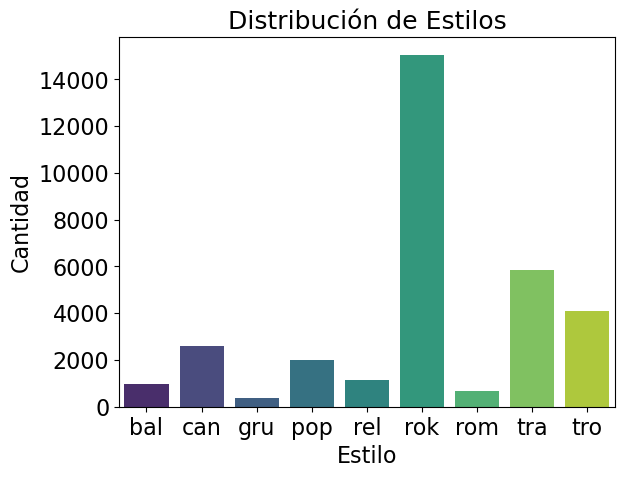

In [78]:
sns.countplot(data=filtered_dataset_final, x='estilo', palette='viridis', hue=filtered_dataset_final['estilo'], legend=False)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel('Estilo', fontsize=16)
plt.ylabel('Cantidad', fontsize=16)
plt.title('Distribución de Estilos', fontsize=18)
plt.show()

### Distribución de variables numéricas

#### **Duración**

Realizamos un histograma de los valores de duración.

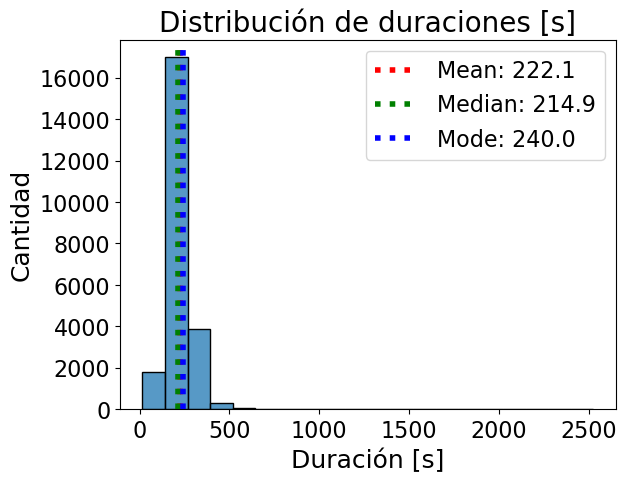

In [79]:
sns.histplot(data=filtered_dataset_final, x='duration_s', bins=20)
mean_val = filtered_dataset_final['duration_s'].mean()
median_val = filtered_dataset_final['duration_s'].median()
mode_val = filtered_dataset_final['duration_s'].mode()[0]
plt.axvline(mean_val, color='red', linestyle=':', linewidth=4, label=f'Mean: {mean_val:.1f}')
plt.axvline(median_val, color='green', linestyle=':', linewidth=4, label=f'Median: {median_val:.1f}')
plt.axvline(mode_val, color='blue', linestyle=':', linewidth=4, label=f'Mode: {mode_val:.1f}')
plt.xlabel('Duración [s]', fontsize=18)
plt.ylabel('Cantidad', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)
plt.title('Distribución de duraciones [s]', fontsize=20)
plt.show()

Se puede ver que existen valores extremos de hasta 42 minutos. Se verificó que algunos de estos registros no presentan error sino que efectivamente tienen duraciones atípicas

In [80]:
filtered_dataset_final.query('duration_s > 1200').head(5)

,song_name,artist_name,lyrics,estilo,song_url,album,release_date,track_name,duration_ms,popularity,...,has_signature,lyrics_no_signature,lyrics_clean_final,len_original,len_final,pct_reduction,year,month,day,duration_s
4536,Perrito,Jaime Sin Tierra,Demasiado romántico<br>Para una piedra tan frí...,pop,https://acordes.lacuerda.net/jaime_sin_tierra/...,El Avión Ya Se Estrelló Y Yo Sigo Volando,1998-05-03,Perrito,1493120.0,7.0,...,False,Demasiado romántico<br>Para una piedra tan frí...,demasiado romántico para una piedra tan fría d...,571,486,0.148862,1998,5,3,1493.120
19206,Hablo De Luz,Zurda,VERSO 1<br>Hay días en que quisiera escapar<br...,rok,https://acordes.lacuerda.net/zurda/hablo_de_luz,Para Viajar,2007-04-01,Hablo de Luz,1478643.0,5.0,...,False,VERSO 1<br>Hay días en que quisiera escapar<br...,hay días en que quisiera escapar por otros mun...,1066,849,0.203565,2007,4,1,1478.643
19210,Los Ultimos,Zurda,Fuiste a viajar por la Puna<br>y atravesaste t...,rok,https://acordes.lacuerda.net/zurda/los_ultimos,Para Viajar,2007-04-01,Los Últimos,1268803.0,8.0,...,False,Fuiste a viajar por la Puna<br>y atravesaste t...,fuiste viajar por puna y atravesaste tus ojos ...,1055,836,0.207583,2007,4,1,1268.803
24964,No Quiero Ser Un Ciudadano,Facundo Cabral,Perdóname señor<br>Pero a veces me canso<br>Pe...,tra,https://acordes.lacuerda.net/facundo_cabral/no...,Ferrocabral (Cruzando Por La Vida En El Tren D...,1995-01-01,"Partida (Incluye Tema: ""No Quiero Ser Un Ciuda...",1341746.0,11.0,...,False,Perdóname señor<br>Pero a veces me canso<br>Pe...,perdóname señor pero veces me canso pero veces...,666,557,0.163664,1995,1,1,1341.746
25926,Herencia Pa Un Hijo Gaucho,Jose Larralde,e|--0--3--0--0--3--0--0--7--0--0--7--0--0--7--...,tra,https://acordes.lacuerda.net/jose_larralde/her...,Herencia Pa' un Hijo Gaucho,1972-04-19,Herencia para un Hijo Gaucho (Segunda Parte - I),1437426.0,37.0,...,True,e|--0--3--0--0--3--0--0--7--0--0--7--0--0--7--...,cuando comienza cantar toca y sigui manera y c...,13820,11783,0.147395,1972,4,19,1437.426


Podemos observar la distribución dentro del rango sin outliers

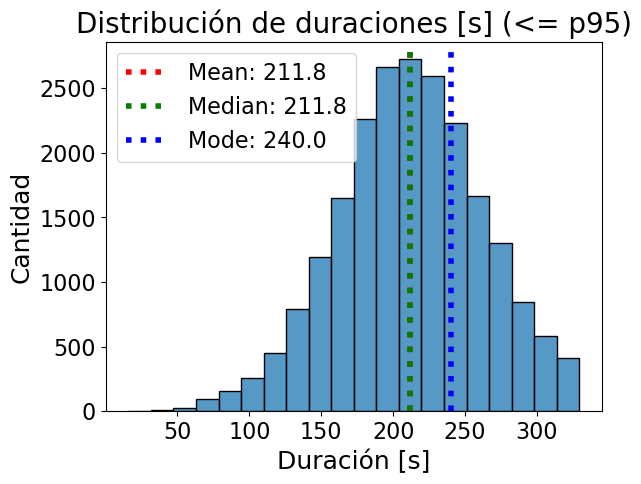

In [81]:
q95_val = filtered_dataset_final['duration_s'].quantile(0.95)
sns.histplot(data=filtered_dataset_final[filtered_dataset_final['duration_s'] <= q95_val], x='duration_s', bins=20)
mean_val = filtered_dataset_final[filtered_dataset_final['duration_s'] <= q95_val]['duration_s'].mean()
median_val = filtered_dataset_final[filtered_dataset_final['duration_s'] <= q95_val]['duration_s'].median()
mode_val = filtered_dataset_final[filtered_dataset_final['duration_s'] <= q95_val]['duration_s'].mode()[0]
plt.axvline(mean_val, color='red', linestyle=':', linewidth=4, label=f'Mean: {mean_val:.1f}')
plt.axvline(median_val, color='green', linestyle=':', linewidth=4, label=f'Median: {median_val:.1f}')
plt.axvline(mode_val, color='blue', linestyle=':', linewidth=4, label=f'Mode: {mode_val:.1f}')
plt.xlabel('Duración [s]', fontsize=18)
plt.ylabel('Cantidad', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)
plt.title('Distribución de duraciones [s] (<= p95)', fontsize=20)
plt.show()

#### **Popularidad**

Gran parte de los registros tienen baja popularidad según el algoritmo de Spotify. Se encuentran outliers de alta popularidad pero su diferencia relativa con los valores más frecuentes es menor.

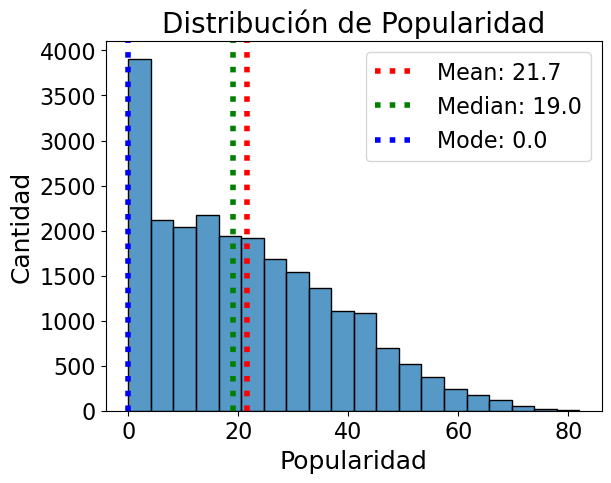

In [82]:
sns.histplot(data=filtered_dataset_final, x='popularity', bins=20)
mean_val = filtered_dataset_final['popularity'].mean()
median_val = filtered_dataset_final['popularity'].median()
mode_val = filtered_dataset_final['popularity'].mode()[0]
plt.axvline(mean_val, color='red', linestyle=':', linewidth=4, label=f'Mean: {mean_val:.1f}')
plt.axvline(median_val, color='green', linestyle=':', linewidth=4, label=f'Median: {median_val:.1f}')
plt.axvline(mode_val, color='blue', linestyle=':', linewidth=4, label=f'Mode: {mode_val:.1f}')
plt.xlabel('Popularidad', fontsize=18)
plt.ylabel('Cantidad', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)
plt.title('Distribución de Popularidad', fontsize=20)
plt.show()

#### **Año de lanzamiento**

Se repite el análisis para el año de lanzamiento.

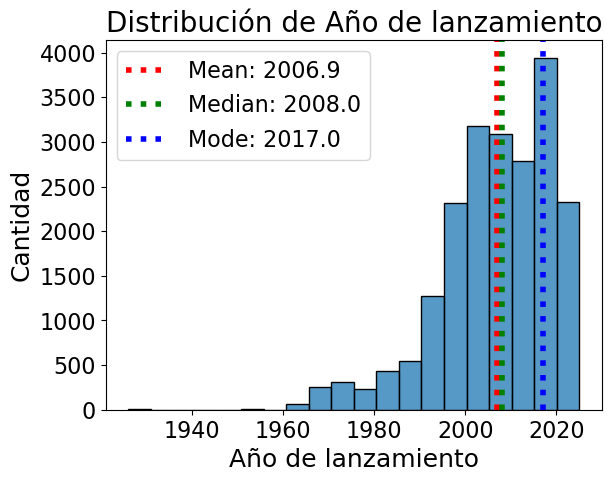

In [83]:
sns.histplot(data=filtered_dataset_final, x='year', bins=20)
mean_val = filtered_dataset_final['year'].mean()
median_val = filtered_dataset_final['year'].median()
mode_val = filtered_dataset_final['year'].mode()[0]
plt.axvline(mean_val, color='red', linestyle=':', linewidth=4, label=f'Mean: {mean_val:.1f}')
plt.axvline(median_val, color='green', linestyle=':', linewidth=4, label=f'Median: {median_val:.1f}')
plt.axvline(mode_val, color='blue', linestyle=':', linewidth=4, label=f'Mode: {mode_val:.1f}')
plt.xlabel('Año de lanzamiento', fontsize=18)
plt.ylabel('Cantidad', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)
plt.title('Distribución de Año de lanzamiento', fontsize=20)
plt.show()

Tomamos solo los registros de 1960 en adelante

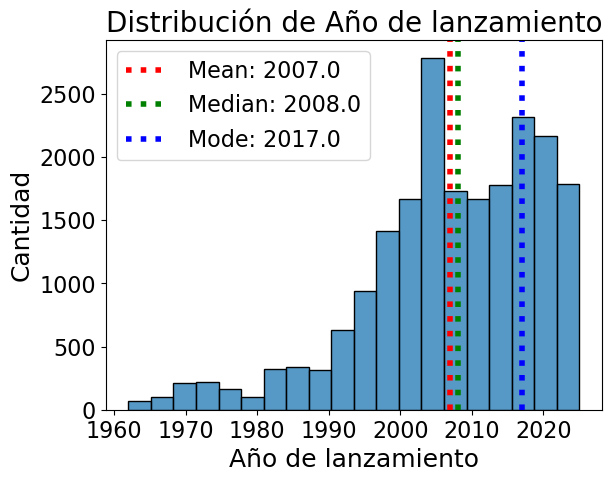

In [84]:
filtered_dataset_final = filtered_dataset_final[filtered_dataset_final['year'] > 1960]

sns.histplot(data=filtered_dataset_final, x='year', bins=20)
mean_val = filtered_dataset_final['year'].mean()
median_val = filtered_dataset_final['year'].median()
mode_val = filtered_dataset_final['year'].mode()[0]
plt.axvline(mean_val, color='red', linestyle=':', linewidth=4, label=f'Mean: {mean_val:.1f}')
plt.axvline(median_val, color='green', linestyle=':', linewidth=4, label=f'Median: {median_val:.1f}')
plt.axvline(mode_val, color='blue', linestyle=':', linewidth=4, label=f'Mode: {mode_val:.1f}')
plt.xlabel('Año de lanzamiento', fontsize=18)
plt.ylabel('Cantidad', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)
plt.title('Distribución de Año de lanzamiento', fontsize=20)
plt.show()

# 3 - Análisis de variable objetivo

Se eligió como variable objetivo el estilo debido a que no proviene de Spotify entonces cuenta con más registros. Además, nos permitiría comparar algunos resultados con uno de los trabajos de referencia.

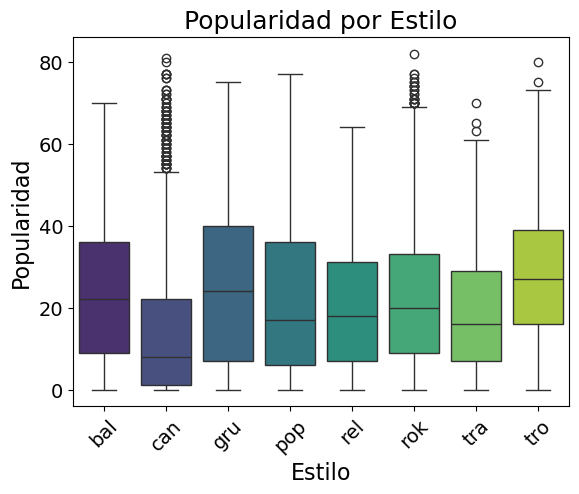

  estilo       mean  median        std  count
7    tro  28.251348    27.0  15.647802   2781
2    gru  25.523132    24.0  19.730334    281
0    bal  23.695860    22.0  17.079181    628
5    rok  22.180746    20.0  15.935147   9837
3    pop  21.980172    17.0  18.405727   1513
4    rel  19.925414    18.0  14.695243    724
6    tra  18.922760    16.0  14.229272   3159
1    can  14.621622     8.0  17.249091   1813


In [85]:
sns.boxplot(data=filtered_dataset_final, x='estilo', y='popularity', palette='viridis', hue=filtered_dataset_final['estilo'], legend=False)
plt.xticks(fontsize=14, rotation=45)
plt.yticks(fontsize=14)
plt.xlabel('Estilo', fontsize=16)
plt.ylabel('Popularidad', fontsize=16)
plt.title('Popularidad por Estilo', fontsize=18)
plt.show()

# Calcular y mostrar media, mediana y desviación estándar de popularidad por estilo
stats = filtered_dataset_final.groupby('estilo')['popularity'].agg(['mean', 'median', 'std', 'count']).reset_index()
print(stats.sort_values(by='mean', ascending=False))

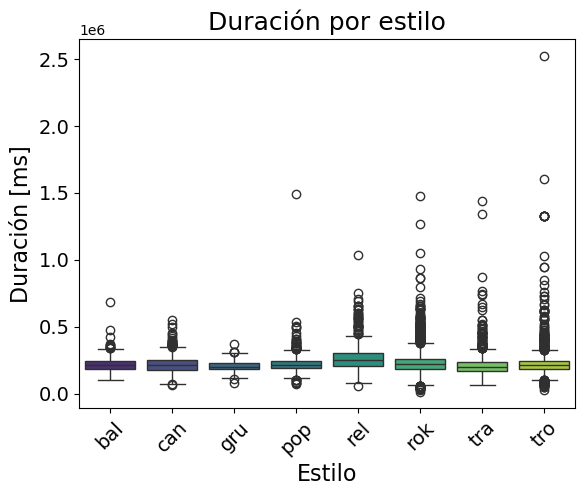

  estilo           mean    median            std  count
4    rel  271947.161602  251719.5   98465.859000    724
5    rok  223968.499136  219800.0   72026.186890   9837
7    tro  223936.308163  213369.0  103845.482254   2781
3    pop  219210.911434  213906.0   57663.771497   1513
0    bal  219053.402866  213599.5   52593.805018    628
1    can  215313.831219  210763.0   54578.379489   1813
2    gru  206805.056940  202345.0   38747.032721    281
6    tra  205787.077240  197840.0   67240.715722   3159


In [86]:
sns.boxplot(data=filtered_dataset_final, x='estilo', y='duration_ms', palette='viridis', hue=filtered_dataset_final['estilo'], legend=False)
plt.xticks(fontsize=14, rotation=45)
plt.yticks(fontsize=14)
plt.xlabel('Estilo', fontsize=16)
plt.ylabel('Duración [ms]', fontsize=16)
plt.title('Duración por estilo', fontsize=18)
plt.show()

# Calcular y mostrar media, mediana y desviación estándar de popularidad por estilo
stats = filtered_dataset_final.groupby('estilo')['duration_ms'].agg(['mean', 'median', 'std', 'count']).reset_index()
print(stats.sort_values(by='mean', ascending=False))

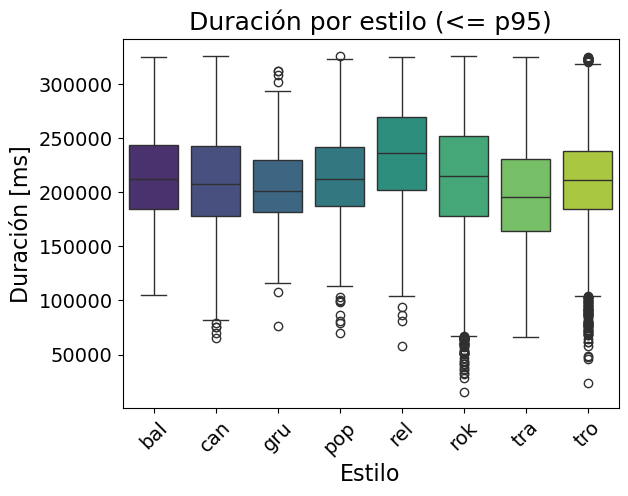

  estilo           mean    median           std  count
4    rel  234859.123711  236132.5  46402.189992    582
0    bal  214839.962418  212697.0  44050.366323    612
3    pop  214741.342123  212389.0  40390.049226   1479
5    rok  213285.099406  215280.0  54243.445056   9255
1    can  210347.642938  208126.5  47124.131735   1756
7    tro  210162.494179  211353.0  45435.031667   2663
2    gru  206208.125000  201679.5  37499.689169    280
6    tra  199033.146484  195466.0  45422.857060   3072


In [87]:
q95_val = filtered_dataset_final['duration_ms'].quantile(0.95)
filtered_q95 = filtered_dataset_final[filtered_dataset_final['duration_ms'] <= q95_val]

sns.boxplot(data=filtered_q95, x='estilo', y='duration_ms', palette='viridis', hue=filtered_q95['estilo'], legend=False)
plt.xticks(fontsize=14, rotation=45)
plt.yticks(fontsize=14)
plt.xlabel('Estilo', fontsize=16)
plt.ylabel('Duración [ms]', fontsize=16)
plt.title('Duración por estilo (<= p95)', fontsize=18)
plt.show()

# Calcular y mostrar media, mediana y desviación estándar de popularidad por estilo para el subconjunto filtrado
stats = filtered_q95.groupby('estilo')['duration_ms'].agg(['mean', 'median', 'std', 'count']).reset_index()
print(stats.sort_values(by='mean', ascending=False))

## Type Token Ratio

Calcularemos el Type Token Ratio (TTR) de cada una de las letras limpias de nuestro set de datos. Definimos el TTR como la cantidad de palabras distintas $V$ (o types) sobre la cantidad total de palabras $N$ (o tokens).

Matemáticamente:

$TTR = \frac{V}{N}$

Particularmente, implementaremos el Moving Average Type Token Ratio (MATTR), que consiste en calcular el TTR para distintas ventanas de longitud $W$ dentro del texto a analizar y calcular su promedio.

Matemáticamente:

$MATTR = \frac{1}{N-W+1} \times \sum_{i=1}^{N-W+1} \frac{V{i}}{W}$

El beneficio de este tipo de implementación es el de poder comparar de igual a igual textos de distinta longitud.

In [88]:
def calculate_ttr(words):
  unique_words = set(words)
  ttr = len(unique_words) / len(words)

  return ttr

def calculate_moving_average_ttr(text, window_size=30):
  words = text.split()
  rolling_ttrs = []

  for i in range(len(words) - window_size + 1):
      current_window = words[i : i + window_size]
      window_ttr = calculate_ttr(current_window)
      rolling_ttrs.append(window_ttr)

  if len(words) == 0:
    avg_ttr = np.nan
  #elif len(words)<window_size:
    #avg_ttr = calculate_ttr(words)
  else:
    avg_ttr = np.array(rolling_ttrs).mean()

  return avg_ttr

Habiendo definido nuestro codigo, procedemos a calcular los TTR para nuestro set de datos

In [89]:
filtered_dataset_final["ttr"] = filtered_dataset_final["lyrics_clean_final"].apply(lambda x: calculate_moving_average_ttr(x))

/tmp/ipykernel_68775/4271494986.py:21: RuntimeWarning: Mean of empty slice.
  avg_ttr = np.array(rolling_ttrs).mean()
/home/sofi/miniconda3/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipykernel_68775/2425145464.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_dataset_final["ttr"] = filtered_dataset_final["lyrics_clean_final"].apply(lambda x: calculate_moving_average_ttr(x))


In [90]:
filtered_dataset_final[['song_name', 'artist_name', 'ttr']].head(5)

,song_name,artist_name,ttr
0,A Mis Amigos,Alberto Cortez,0.939186
2,Amor Desolado,Alberto Cortez,0.777493
11,Caminabamos,Alberto Cortez,0.904058
12,Carta A Mi Viejo,Alberto Cortez,0.902222
20,Cuando Te Asomes Al Amor,Alberto Cortez,0.853230


Podemos visualizar su distribución y analizar su comportamiento:

In [91]:
filtered_dataset_final['ttr'].describe()

count    20602.000000
mean         0.807840
std          0.089832
min          0.082353
25%          0.764155
50%          0.826316
75%          0.870690
max          0.998810
Name: ttr, dtype: float64

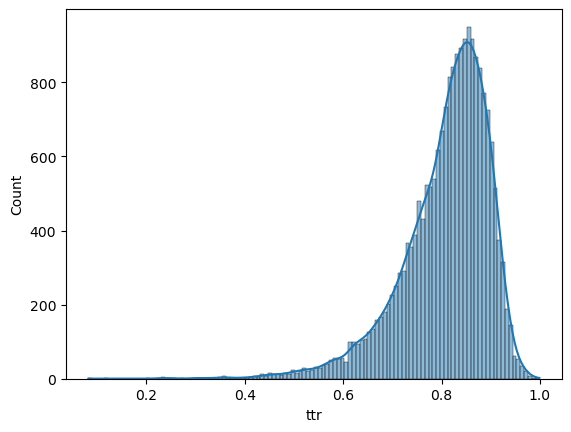

In [92]:
sns.histplot(data=filtered_dataset_final, x='ttr', kde=True)
plt.show()

Como podemos ver, la distribución de los TTR de nuestras letras muestra una forma asimétrica, con una gran cola hacia el lado izquierdo.

Vamos a visualizar ahora la distribución para cada uno de los estilos:

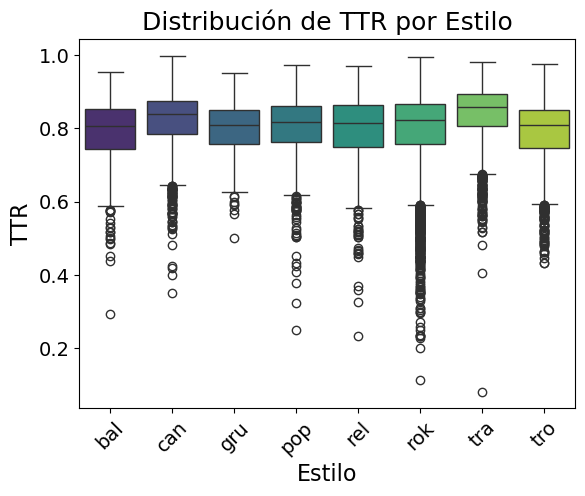

         count      mean       std       min       25%       50%       75%  \
estilo                                                                       
tra     3155.0  0.841659  0.073780  0.082353  0.806225  0.858949  0.893678   
can     1809.0  0.822130  0.079006  0.351515  0.783750  0.839080  0.876033   
pop     1505.0  0.804539  0.082142  0.249084  0.763661  0.816667  0.861011   
rok     9742.0  0.802022  0.095450  0.113441  0.757081  0.822788  0.867572   
gru      281.0  0.798151  0.077561  0.500000  0.757083  0.808974  0.851488   
rel      715.0  0.792168  0.100992  0.233333  0.749023  0.816000  0.862458   
tro     2768.0  0.791568  0.083736  0.431515  0.746958  0.810039  0.849807   
bal      627.0  0.788823  0.089756  0.293961  0.743341  0.806878  0.853060   

             max  
estilo            
tra     0.980357  
can     0.998810  
pop     0.972464  
rok     0.995035  
gru     0.950694  
rel     0.969333  
tro     0.974667  
bal     0.953333  

Desviación estándar de TTR p

In [93]:
sns.boxplot(data=filtered_dataset_final, x='estilo', y='ttr', palette='viridis', hue=filtered_dataset_final['estilo'], legend=False)
plt.xticks(fontsize=14, rotation=45)
plt.yticks(fontsize=14)
plt.xlabel('Estilo', fontsize=16)
plt.ylabel('TTR', fontsize=16)
plt.title('Distribución de TTR por Estilo', fontsize=18)
plt.show()

# Calcular estadísticas descriptivas para la columna ttr por estilo
ttr_stats_by_style = filtered_dataset_final.groupby('estilo')['ttr'].describe()
print(ttr_stats_by_style.sort_values(by='mean', ascending=False))

# También mostrar la desviación estándar explícitamente por estilo
ttr_std_by_style = filtered_dataset_final.groupby('estilo')['ttr'].std()
print("\nDesviación estándar de TTR por estilo:")
print(ttr_std_by_style.sort_values())

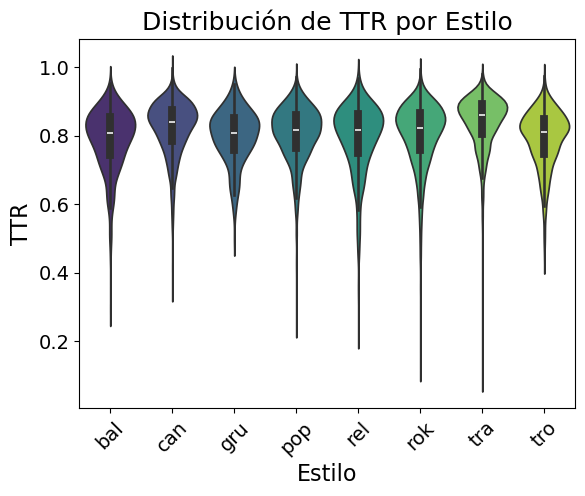

         count      mean       std       min       25%       50%       75%  \
estilo                                                                       
tra     3155.0  0.841659  0.073780  0.082353  0.806225  0.858949  0.893678   
can     1809.0  0.822130  0.079006  0.351515  0.783750  0.839080  0.876033   
pop     1505.0  0.804539  0.082142  0.249084  0.763661  0.816667  0.861011   
rok     9742.0  0.802022  0.095450  0.113441  0.757081  0.822788  0.867572   
gru      281.0  0.798151  0.077561  0.500000  0.757083  0.808974  0.851488   
rel      715.0  0.792168  0.100992  0.233333  0.749023  0.816000  0.862458   
tro     2768.0  0.791568  0.083736  0.431515  0.746958  0.810039  0.849807   
bal      627.0  0.788823  0.089756  0.293961  0.743341  0.806878  0.853060   

             max  
estilo            
tra     0.980357  
can     0.998810  
pop     0.972464  
rok     0.995035  
gru     0.950694  
rel     0.969333  
tro     0.974667  
bal     0.953333  

Desviación estándar de TTR p

In [94]:
sns.violinplot(data=filtered_dataset_final, x='estilo', y='ttr', hue='estilo', palette='viridis', legend=False)
plt.xticks(fontsize=14, rotation=45)
plt.yticks(fontsize=14)
plt.xlabel('Estilo', fontsize=16)
plt.ylabel('TTR', fontsize=16)
plt.title('Distribución de TTR por Estilo', fontsize=18)
plt.show()

# Calcular estadísticas descriptivas para la columna ttr por estilo
ttr_stats_by_style = filtered_dataset_final.groupby('estilo')['ttr'].describe()
print(ttr_stats_by_style.sort_values(by='mean', ascending=False))

# También mostrar la desviación estándar explícitamente por estilo
ttr_std_by_style = filtered_dataset_final.groupby('estilo')['ttr'].std()
print("\nDesviación estándar de TTR por estilo:")
print(ttr_std_by_style.sort_values())

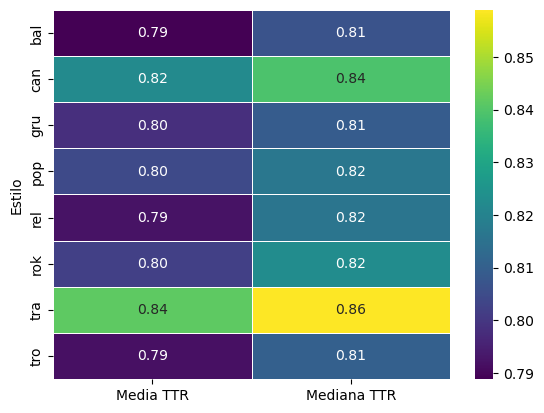

In [95]:
summary_stats = filtered_dataset_final.groupby('estilo')['ttr'].agg(['mean', 'median']).reset_index()
summary_stats.columns = ['Estilo', 'Media TTR', 'Mediana TTR']
heatmap_data = summary_stats.set_index('Estilo')

sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap='viridis', linewidths=.5)
plt.show()

# 4 - Resultados


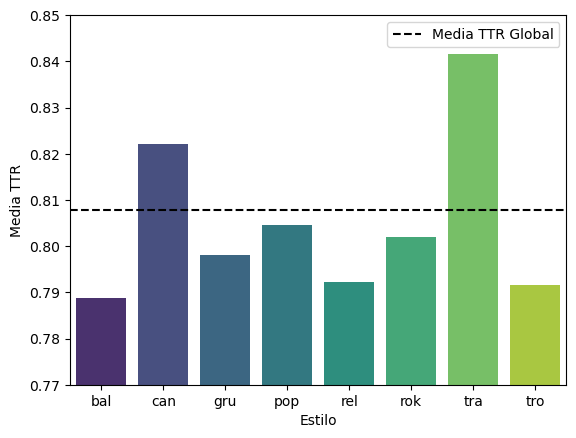

In [96]:
ttr_mean_genre = filtered_dataset_final.groupby('estilo')['ttr'].agg('mean').reset_index()
ttr_mean_genre.columns = ['Estilo', 'Media TTR']
ttr_mean = filtered_dataset_final['ttr'].mean()

sns.barplot(data=ttr_mean_genre, x='Estilo', y='Media TTR', palette='viridis', hue=ttr_mean_genre['Estilo'], legend=False)
plt.axhline(ttr_mean, color='black', linestyle='--', linewidth=1.5, label='Media TTR Global')

plt.ylim(0.77, 0.85)
plt.legend()

plt.show()

Similarmente a como lo hace K. Kettunen en su trabajo 'Can Type-Token Ratio be Used to Show Morphological Complexity of Languages?', al no haber una medida estándar comparable para el valor del TTR calculado, haremos nuestras observaciones basándonos en el TTR de cada estilo contra la media general del set de datos.

Podemos entonces notar que los estilos con menor TTR respecto a la media son Religioso y Tropical y que los estilos con mayor TTR son Tradicional y Cantautor.

Cabe destacar que el valor de esta métrica no solo se ve influenciada por la diversidad léxica de las letras sino también por su estructura. Es decir que aquellos estilos que posean una estructura musical apalancada en los estribillos tendran usualmente un TTR mas bajo, mientras que aquellos con una estructura más lineal sin repeticiones, uno más alto. A la vez, esta forma de calcular el TTR con ventanas ponderará más aquellas palabras ubicadas en la mitad de la letra (que aparecerán en las ventanas $W$ veces) que aquellas ubicadas al principio y al final (que solamente serán consideradas una vez). Es por esto que aquellos estilos donde los estribillos se encuentren en la mitad de la letra poseerán posiblemente un TTR más bajo.

Consideramos entonces el resultado obtenido como esperado, teniendo en consideracion las estructuras y los topicos usuales de las canciones de estos estilos.